<a href="https://colab.research.google.com/github/erfanshahabi1/From-Global-Thresholds-to....-/blob/main/Notebooks/SPRINGF4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# نصب کتابخانه‌های لازم (در صورت نیاز)
!pip install xgboost shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')


In [ ]:
from google.colab import files

print("لطفاً ۴ فایل با نام‌های زیر را آپلود کن:")
print("SPRIN_cleanedNE.csv, SPRING_cleanedNW.csv, SPRING_cleanedSE.csv, SPRING_cleanedSW.csv")
uploaded = files.upload()


لطفاً ۴ فایل با نام‌های زیر را آپلود کن:
SPRIN_cleanedNE.csv, SPRING_cleanedNW.csv, SPRING_cleanedSE.csv, SPRING_cleanedSW.csv


Saving spring_cleanedNE.csv to spring_cleanedNE.csv
Saving spring_cleanedNW.csv to spring_cleanedNW.csv
Saving spring_cleanedSE.csv to spring_cleanedSE.csv
Saving spring_cleanedSW.csv to spring_cleanedSW.csv


In [ ]:
import pandas as pd

# لیست مناطق
regions = ['NW', 'NE', 'SW', 'SE']

# دیکشنری برای ذخیره داده‌ها
data = {}

# بارگذاری داده برای هر منطقه
for region in regions:
    file_name = f'spring_cleaned{region}.csv'  # فایل باید در مسیر کاری باشه
    df = pd.read_csv(file_name)
    data[region] = df
    print(f"✅ {region} loaded: {df.shape[0]} rows, {df.shape[1]} columns")


✅ NW loaded: 6192 rows, 50 columns
✅ NE loaded: 6192 rows, 50 columns
✅ SW loaded: 5246 rows, 50 columns
✅ SE loaded: 4644 rows, 50 columns


In [ ]:
# حذف سطرهایی که دارای مقدار گمشده (NaN) هستند در هر منطقه
for region in regions:
    original_rows = data[region].shape[0]
    data[region] = data[region].dropna().reset_index(drop=True)
    cleaned_rows = data[region].shape[0]
    print(f"🧹 {region}: {original_rows - cleaned_rows} rows with missing values removed.")


🧹 NW: 0 rows with missing values removed.
🧹 NE: 3 rows with missing values removed.
🧹 SW: 0 rows with missing values removed.
🧹 SE: 0 rows with missing values removed.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# تعریف مناطق و مخاطرات
regions = ['NW', 'NE', 'SW', 'SE']
hazards = [
    'hazard_drought',
    'hazard_rain_deficit',
    'hazard_heatwave',
    'hazard_hot_and_dry',
    'hazard_cold_spell',
    'hazard_radiation_deficit',
    'hazard_temperature_accumulation_deficit'
]

shap_top_features = {
    # drought
    ('NW', 'hazard_drought'): ['GDD', 'lai_lv', 'VPD_anom', 'RH_anom', 'VPD', 'RH', 'lai_hv'],
    ('NE', 'hazard_drought'): ['GDD', 'lai_lv', 'VPD_anom', 'RH_anom', 'VPD', 'RH', 'lai_hv'],
    ('SW', 'hazard_drought'): ['GDD', 'lai_lv', 'VPD_anom', 'RH_anom', 'VPD', 'RH', 'lai_hv'],
    ('SE', 'hazard_drought'): ['GDD', 'lai_lv', 'VPD_anom', 'RH_anom', 'VPD', 'RH', 'lai_hv'],

    ('NW', 'hazard_rain_deficit'): ['spi_seasonal', 'swvl3', 'avg_slhtf', 'GDD', 'swvl2', 'swvl1'],
    ('NE', 'hazard_rain_deficit'): ['spi_seasonal', 'swvl3', 'avg_slhtf', 'GDD', 'swvl2', 'swvl1' ],
    ('SW', 'hazard_rain_deficit'): ['spi_seasonal', 'swvl3', 'avg_slhtf', 'GDD', 'swvl2', 'swvl1' ],
    ('SE', 'hazard_rain_deficit'): ['spi_seasonal', 'swvl3', 'avg_slhtf', 'GDD', 'swvl2', 'swvl1' ],

    ('NW', 'hazard_heatwave'): ['VPD_anom', 'VPD', 'stl2', 'stl1', 'swvl1'],
    ('NE', 'hazard_heatwave'): ['VPD_anom', 'VPD', 'stl2', 'stl1', 'swvl1'],
    ('SW', 'hazard_heatwave'): ['VPD_anom', 'VPD', 'stl2', 'stl1', 'swvl1'],
    ('SE', 'hazard_heatwave'): ['VPD_anom', 'VPD', 'stl2', 'stl1', 'swvl1'],

    ('NW', 'hazard_hot_and_dry'): ['lai_lv', 'RH_anom', 'RH', 'lai_hv', 'stl2', 'stl1'],
    ('NE', 'hazard_hot_and_dry'): ['lai_lv', 'VPD_anom', 'RH_anom', 'VPD', 'RH', 'lai_hv', 'stl2', 'stl1'],
    ('SW', 'hazard_hot_and_dry'): ['lai_lv', 'VPD_anom', 'RH_anom', 'VPD', 'RH', 'lai_hv', 'stl2', 'stl1'],
    ('SE', 'hazard_hot_and_dry'): ['GDD', 'lai_lv', 'VPD_anom', 'RH_anom', 'VPD', 'RH', 'lai_hv', 'stl2', 'stl1'],

    ('NW', 'hazard_cold_spell'): ['t2m_anom','RH', 'swvl2', 'swvl3', 'swvl4'],
    ('NE', 'hazard_cold_spell'): ['t2m_anom','RH', 'swvl2', 'swvl3', 'swvl4'],
    ('SW', 'hazard_cold_spell'): ['RH_anom','RH', 'tp', 'swvl3', 'swvl4'],
    ('SE', 'hazard_cold_spell'): ['t2m_anom','RH', 'swvl2', 'swvl3', 'swvl4'],

    ('NW', 'hazard_radiation_deficit'): ['RH', 'v10', 'RH_anom', 'e', 'lai_lv', 'u10', 'lai_hv'],
    ('NE', 'hazard_radiation_deficit'): ['RH', 'v10', 'RH_anom', 'e', 'lai_lv', 'u10', 'lai_hv'],
    ('SW', 'hazard_radiation_deficit'): ['RH', 'v10', 'RH_anom', 'e', 'lai_lv', 'u10', 'lai_hv'],
    ('SE', 'hazard_radiation_deficit'): ['RH', 'v10', 'RH_anom', 'e', 'lai_lv', 'u10', 'lai_hv'],

    ('NW', 'hazard_temperature_accumulation_deficit'): ['RH', 'lai_lv', 'lai_hv','avg_slhtf'],
    ('NE', 'hazard_temperature_accumulation_deficit'): ['RH', 'lai_lv', 'lai_hv','t2m_anom'],
    ('SW', 'hazard_temperature_accumulation_deficit'): ['RH', 'lai_lv', 'lai_hv','avg_slhtf'],
    ('SE', 'hazard_temperature_accumulation_deficit'): ['RH', 'lai_lv', 'lai_hv','avg_slhtf'],
}


# دیکشنری خروجی
prepared_data = {}

for region in regions:
    df = data[region]

    for hazard in hazards:
        if hazard not in df.columns:
            continue

        key = (region, hazard)
        keep_features = shap_top_features.get(key)
        if not keep_features:
            print(f"⚠️ No SHAP features found for {region} / {hazard}")
            continue

        # ساخت X و y فقط با ویژگی‌های مهم
        X = df[keep_features].copy()
        y = df[hazard]

        # حذف ردیف‌های گمشده (در صورت وجود)
        combined = pd.concat([X, y], axis=1).dropna()
        X = combined[keep_features]
        y = combined[hazard]

        # تقسیم train/test
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.3, random_state=42, stratify=y
        )

        # استانداردسازی
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # ذخیره
        prepared_data[key] = {
            'X_train': X_train_scaled,
            'X_test': X_test_scaled,
            'y_train': y_train.reset_index(drop=True),
            'y_test': y_test.reset_index(drop=True),
            'feature_names': X.columns.tolist()
        }

        print(f"✅ {region} / {hazard}: {X.shape[1]} features, {X.shape[0]} samples")


✅ NW / hazard_drought: 7 features, 6192 samples
✅ NW / hazard_rain_deficit: 6 features, 6192 samples
✅ NW / hazard_heatwave: 5 features, 6192 samples
✅ NW / hazard_hot_and_dry: 6 features, 6192 samples
✅ NW / hazard_cold_spell: 5 features, 6192 samples
✅ NW / hazard_radiation_deficit: 7 features, 6192 samples
✅ NW / hazard_temperature_accumulation_deficit: 4 features, 6192 samples
✅ NE / hazard_drought: 7 features, 6189 samples
✅ NE / hazard_rain_deficit: 6 features, 6189 samples
✅ NE / hazard_heatwave: 5 features, 6189 samples
✅ NE / hazard_hot_and_dry: 8 features, 6189 samples
✅ NE / hazard_cold_spell: 5 features, 6189 samples
✅ NE / hazard_radiation_deficit: 7 features, 6189 samples
✅ NE / hazard_temperature_accumulation_deficit: 4 features, 6189 samples
✅ SW / hazard_drought: 7 features, 5246 samples
✅ SW / hazard_rain_deficit: 6 features, 5246 samples
✅ SW / hazard_heatwave: 5 features, 5246 samples
✅ SW / hazard_hot_and_dry: 8 features, 5246 samples
✅ SW / hazard_cold_spell: 5 fe

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, f1_score, balanced_accuracy_score
from collections import Counter
import pandas as pd
import numpy as np

cv_results = {}

for region in regions:
    df = data[region]

    for hazard in hazards:
        if hazard not in df.columns:
            continue

        key = (region, hazard)
        keep_features = shap_top_features.get(key)
        if not keep_features:
            print(f"⚠️ No SHAP features found for {region} / {hazard}")
            continue

        X = df[keep_features].copy()
        y = df[hazard]

        # حذف ردیف‌های گمشده
        combined = pd.concat([X, y], axis=1).dropna()
        X = combined[keep_features]
        y = combined[hazard]

        # مدیریت عدم‌توازن کلاس
        class_counts = Counter(y)
        if 0 in class_counts and 1 in class_counts and class_counts[1] != 0:
            scale_pos_weight = class_counts[0] / class_counts[1]
        else:
            scale_pos_weight = 1  # fallback اگر فقط یک کلاس موجود بود

        # استانداردسازی کل داده
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)

        # تعریف مدل پایه
        model = XGBClassifier(
            booster='gbtree',               # صراحتاً تعریف شود برای SHAP
            subsample=0.8,
            colsample_bytree=0.8,
            use_label_encoder=False,
            eval_metric='logloss',
            random_state=42
        )

        # پارامترهای قابل جست‌وجو
        param_grid = {
            'n_estimators': [100, 300],
            'max_depth': [3, 5],
            'learning_rate': [0.01, 0.03],
            'reg_lambda': [1, 3],
            'reg_alpha': [0, 1],
            'scale_pos_weight': [scale_pos_weight]
        }

        # تعریف Cross-Validation
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

        # معیارهای ارزیابی
        scoring = {
            'f1': make_scorer(f1_score),
            'balanced_accuracy': make_scorer(balanced_accuracy_score)
        }

        # جست‌وجوی شبکه‌ای
        grid = GridSearchCV(
            estimator=model,
            param_grid=param_grid,
            cv=skf,
            scoring=scoring,
            refit='balanced_accuracy',
            verbose=0,
            n_jobs=-1
        )

        # آموزش
        grid.fit(X_scaled, y)

        # استخراج نتایج
        best_model = grid.best_estimator_
        best_params = grid.best_params_

        mean_f1 = grid.cv_results_['mean_test_f1'][grid.best_index_]
        std_f1 = grid.cv_results_['std_test_f1'][grid.best_index_]
        mean_bal_acc = grid.cv_results_['mean_test_balanced_accuracy'][grid.best_index_]
        std_bal_acc = grid.cv_results_['std_test_balanced_accuracy'][grid.best_index_]

        # ذخیره در دیکشنری خروجی
        cv_results[key] = {
            'best_params': best_params,
            'mean_f1': mean_f1,
            'std_f1': std_f1,
            'mean_bal_acc': mean_bal_acc,
            'std_bal_acc': std_bal_acc,
            'best_model': best_model
        }

        print(f"✅ {region} / {hazard} – F1: {mean_f1:.3f}±{std_f1:.3f}, "
              f"BalancedAcc: {mean_bal_acc:.3f}±{std_bal_acc:.3f}, BestParams: {best_params}")


✅ NW / hazard_drought – F1: 0.769±0.012, BalancedAcc: 0.848±0.010, BestParams: {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 300, 'reg_alpha': 0, 'reg_lambda': 1, 'scale_pos_weight': 2.3416082029141934}
✅ NW / hazard_rain_deficit – F1: 0.647±0.030, BalancedAcc: 0.966±0.006, BestParams: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300, 'reg_alpha': 0, 'reg_lambda': 3, 'scale_pos_weight': 24.068825910931174}
✅ NW / hazard_heatwave – F1: 0.865±0.018, BalancedAcc: 0.965±0.013, BestParams: {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 300, 'reg_alpha': 1, 'reg_lambda': 3, 'scale_pos_weight': 9.882249560632689}
✅ NW / hazard_hot_and_dry – F1: 0.817±0.009, BalancedAcc: 0.949±0.006, BestParams: {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 300, 'reg_alpha': 1, 'reg_lambda': 3, 'scale_pos_weight': 10.176895306859207}
✅ NW / hazard_cold_spell – F1: 0.716±0.028, BalancedAcc: 0.972±0.019, BestParams: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 1

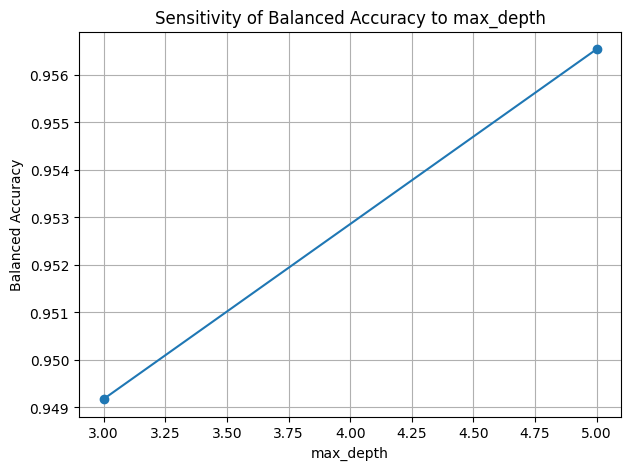

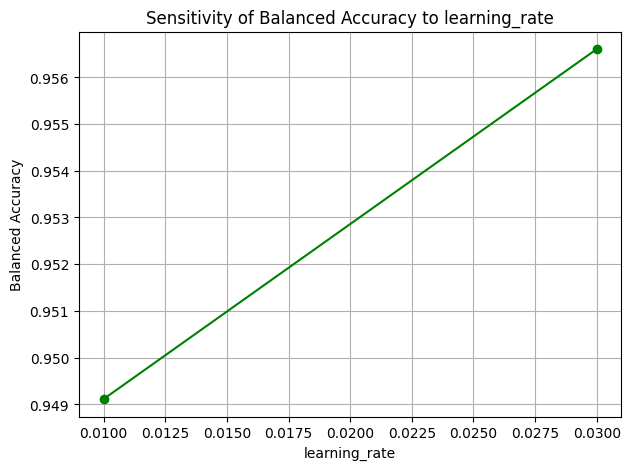

In [ ]:
import matplotlib.pyplot as plt

# استخراج نتایج کامل gridsearch
results_df = pd.DataFrame(grid.cv_results_)

# ۱) بررسی sensitivity نسبت به max_depth
grouped_depth = results_df.groupby('param_max_depth')['mean_test_balanced_accuracy'].mean()

plt.figure(figsize=(7,5))
plt.plot(grouped_depth.index, grouped_depth.values, marker='o')
plt.title("Sensitivity of Balanced Accuracy to max_depth")
plt.xlabel("max_depth")
plt.ylabel("Balanced Accuracy")
plt.grid(True)
plt.show()


# برای max_depth

# برای learning_rate

# ۲) بررسی sensitivity نسبت به learning_rate
grouped_lr = results_df.groupby('param_learning_rate')['mean_test_balanced_accuracy'].mean()

plt.figure(figsize=(7,5))
plt.plot(grouped_lr.index, grouped_lr.values, marker='o', color='green')
plt.title("Sensitivity of Balanced Accuracy to learning_rate")
plt.xlabel("learning_rate")
plt.ylabel("Balanced Accuracy")
plt.grid(True)
plt.show()


🔍 SHAP Summary for NW / hazard_drought


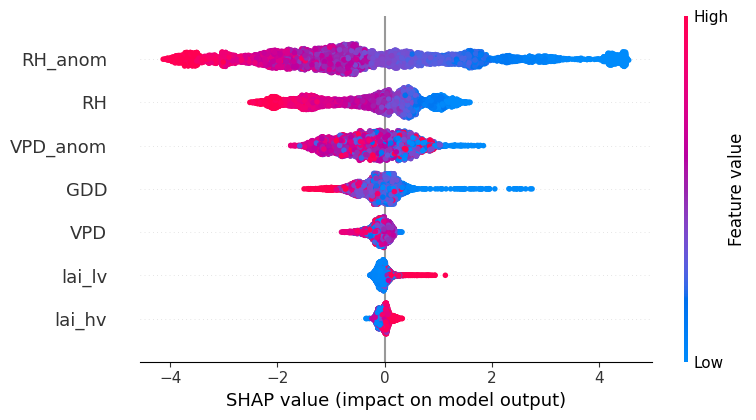

📌 SHAP Summary – hazard_drought
🔷 NW – Top 5 Features:
  • RH_anom: 1.6663000583648682
  • RH: 0.7997999787330627
  • VPD_anom: 0.5268999934196472
  • GDD: 0.2856999933719635
  • VPD: 0.1453000009059906
------------------------------------------------------------

🔍 SHAP Summary for NW / hazard_rain_deficit


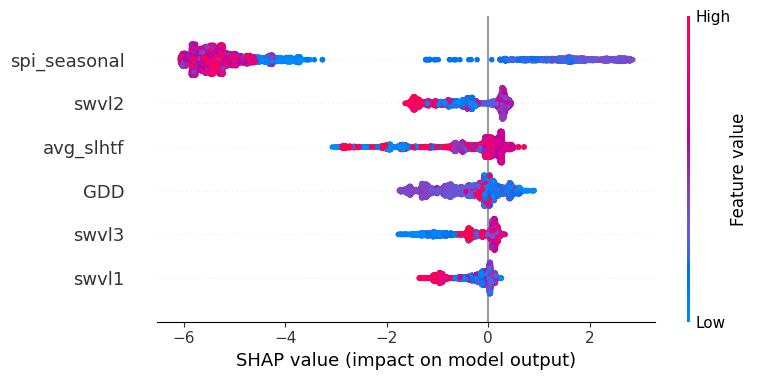

📌 SHAP Summary – hazard_rain_deficit
🔷 NW – Top 5 Features:
  • spi_seasonal: 4.632699966430664
  • swvl2: 0.6299999952316284
  • avg_slhtf: 0.5515000224113464
  • GDD: 0.5115000009536743
  • swvl3: 0.3894999921321869
------------------------------------------------------------

🔍 SHAP Summary for NW / hazard_heatwave


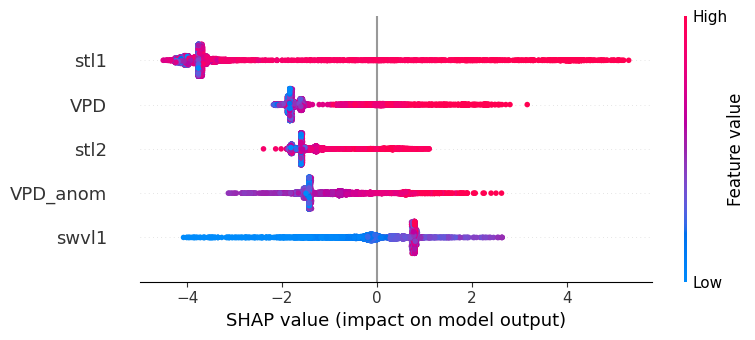

📌 SHAP Summary – hazard_heatwave
🔷 NW – Top 5 Features:
  • stl1: 3.50819993019104
  • VPD: 1.4783999919891357
  • stl2: 1.3552000522613525
  • VPD_anom: 1.1309000253677368
  • swvl1: 0.689300000667572
------------------------------------------------------------

🔍 SHAP Summary for NW / hazard_hot_and_dry


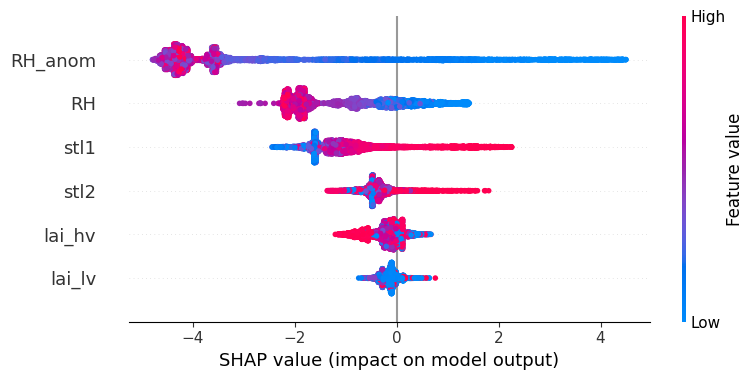

📌 SHAP Summary – hazard_hot_and_dry
🔷 NW – Top 5 Features:
  • RH_anom: 3.518199920654297
  • RH: 1.2289999723434448
  • stl1: 1.152999997138977
  • stl2: 0.4336000084877014
  • lai_hv: 0.28049999475479126
------------------------------------------------------------

🔍 SHAP Summary for NW / hazard_cold_spell


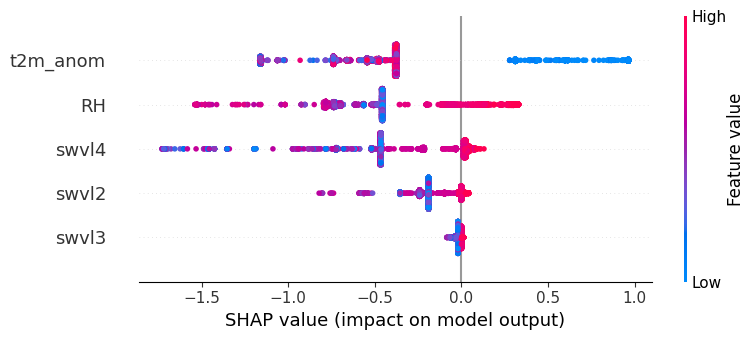

📌 SHAP Summary – hazard_cold_spell
🔷 NW – Top 5 Features:
  • t2m_anom: 0.5697000026702881
  • RH: 0.5031999945640564
  • swvl4: 0.31470000743865967
  • swvl2: 0.14550000429153442
  • swvl3: 0.012900000438094139
------------------------------------------------------------

🔍 SHAP Summary for NW / hazard_radiation_deficit


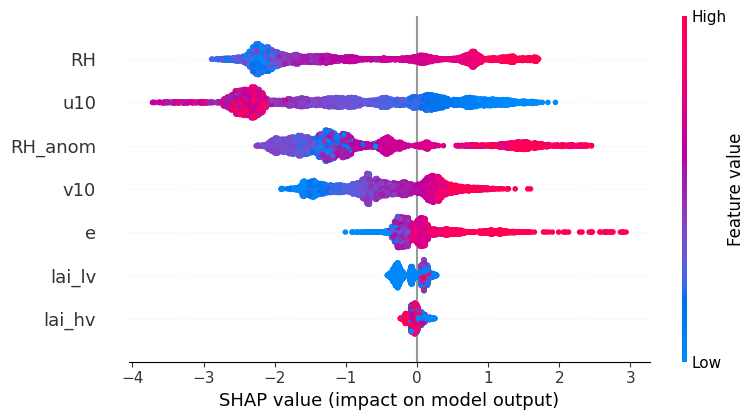

📌 SHAP Summary – hazard_radiation_deficit
🔷 NW – Top 5 Features:
  • RH: 1.5225000381469727
  • u10: 1.3832000494003296
  • RH_anom: 1.2562999725341797
  • v10: 0.6506999731063843
  • e: 0.28439998626708984
------------------------------------------------------------

🔍 SHAP Summary for NW / hazard_temperature_accumulation_deficit


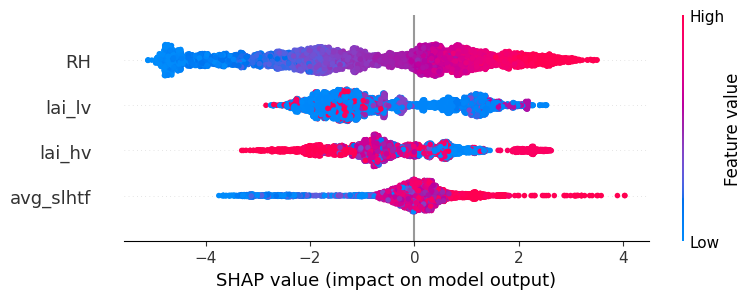

📌 SHAP Summary – hazard_temperature_accumulation_deficit
🔷 NW – Top 5 Features:
  • RH: 1.916599988937378
  • lai_lv: 1.2419999837875366
  • lai_hv: 0.9702000021934509
  • avg_slhtf: 0.5652999877929688
------------------------------------------------------------

🔍 SHAP Summary for NE / hazard_drought


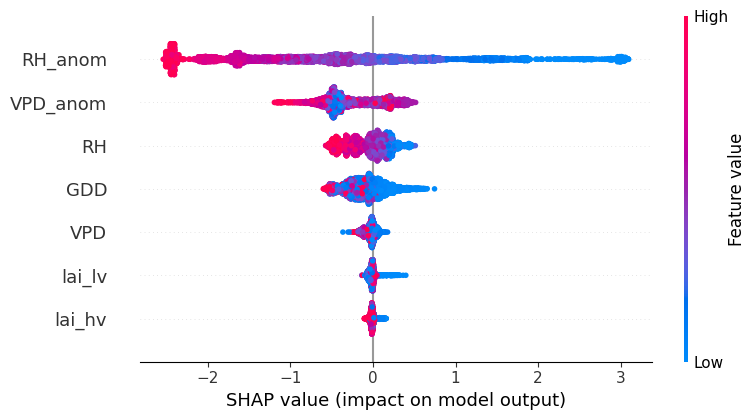

📌 SHAP Summary – hazard_drought
🔷 NE – Top 5 Features:
  • RH_anom: 1.2038999795913696
  • VPD_anom: 0.36000001430511475
  • RH: 0.19589999318122864
  • GDD: 0.19349999725818634
  • VPD: 0.0502999983727932
------------------------------------------------------------

🔍 SHAP Summary for NE / hazard_rain_deficit


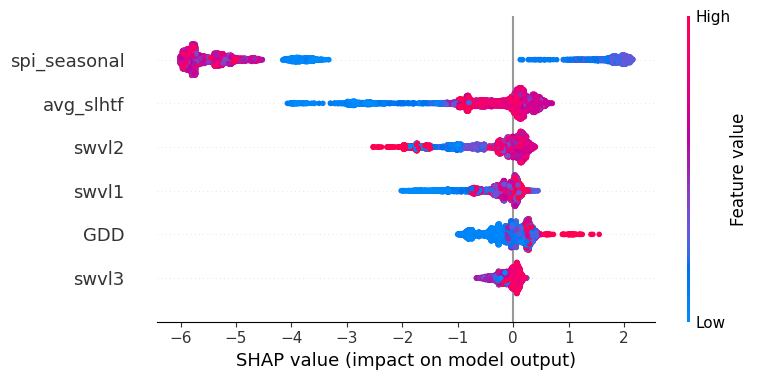

📌 SHAP Summary – hazard_rain_deficit
🔷 NE – Top 5 Features:
  • spi_seasonal: 4.6234002113342285
  • avg_slhtf: 0.6279000043869019
  • swvl2: 0.4602999985218048
  • swvl1: 0.3230000138282776
  • GDD: 0.2720000147819519
------------------------------------------------------------

🔍 SHAP Summary for NE / hazard_heatwave


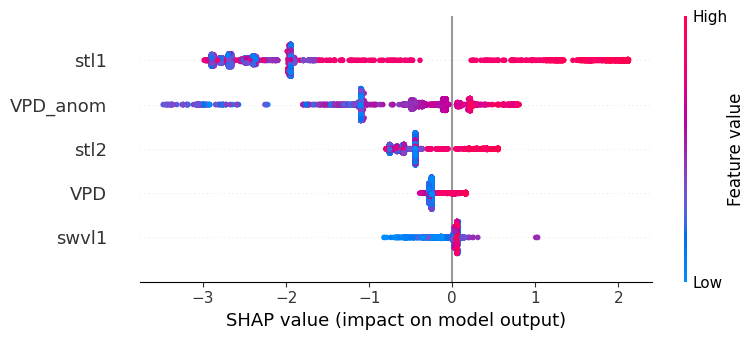

📌 SHAP Summary – hazard_heatwave
🔷 NE – Top 5 Features:
  • stl1: 2.2464001178741455
  • VPD_anom: 0.6905999779701233
  • stl2: 0.5357999801635742
  • VPD: 0.23180000483989716
  • swvl1: 0.06989999860525131
------------------------------------------------------------

🔍 SHAP Summary for NE / hazard_hot_and_dry


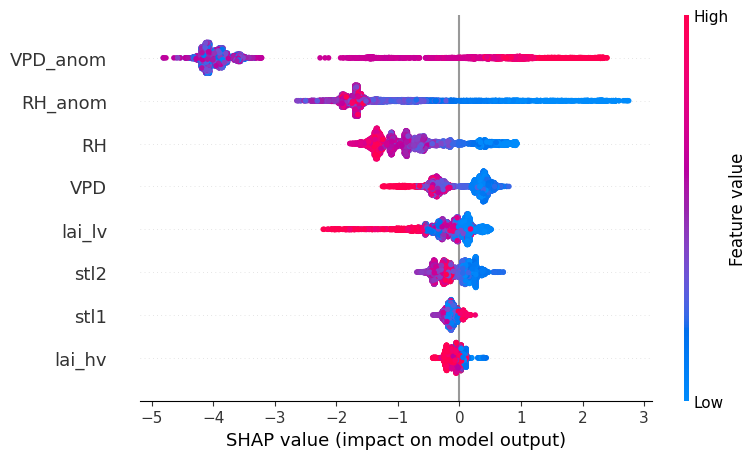

📌 SHAP Summary – hazard_hot_and_dry
🔷 NE – Top 5 Features:
  • VPD_anom: 3.1809000968933105
  • RH_anom: 1.500499963760376
  • RH: 0.8823000192642212
  • VPD: 0.3953000009059906
  • lai_lv: 0.2921000123023987
------------------------------------------------------------

🔍 SHAP Summary for NE / hazard_cold_spell


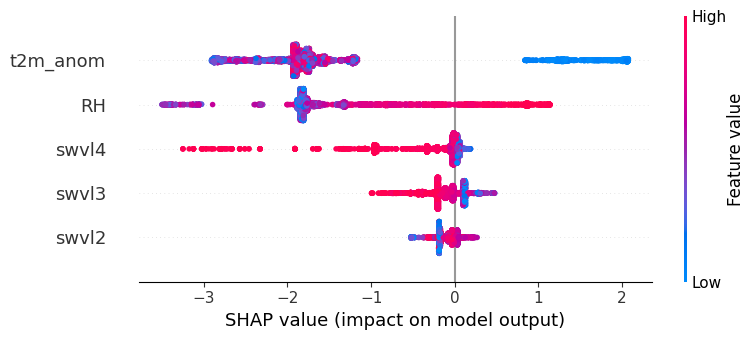

📌 SHAP Summary – hazard_cold_spell
🔷 NE – Top 5 Features:
  • t2m_anom: 1.8633999824523926
  • RH: 1.5166000127792358
  • swvl4: 0.20550000667572021
  • swvl3: 0.18080000579357147
  • swvl2: 0.10189999639987946
------------------------------------------------------------

🔍 SHAP Summary for NE / hazard_radiation_deficit


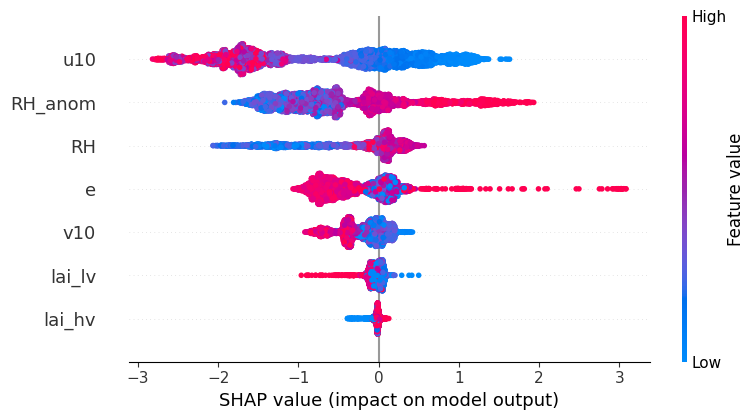

📌 SHAP Summary – hazard_radiation_deficit
🔷 NE – Top 5 Features:
  • u10: 1.017300009727478
  • RH_anom: 0.771399974822998
  • RH: 0.4424999952316284
  • e: 0.43070000410079956
  • v10: 0.24169999361038208
------------------------------------------------------------

🔍 SHAP Summary for NE / hazard_temperature_accumulation_deficit


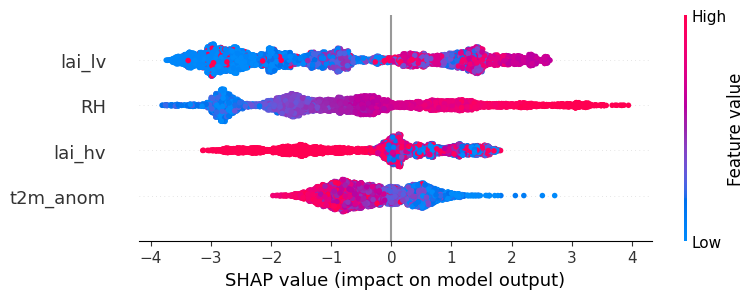

📌 SHAP Summary – hazard_temperature_accumulation_deficit
🔷 NE – Top 5 Features:
  • lai_lv: 1.767300009727478
  • RH: 1.5332000255584717
  • lai_hv: 0.9417999982833862
  • t2m_anom: 0.6474000215530396
------------------------------------------------------------

🔍 SHAP Summary for SW / hazard_drought


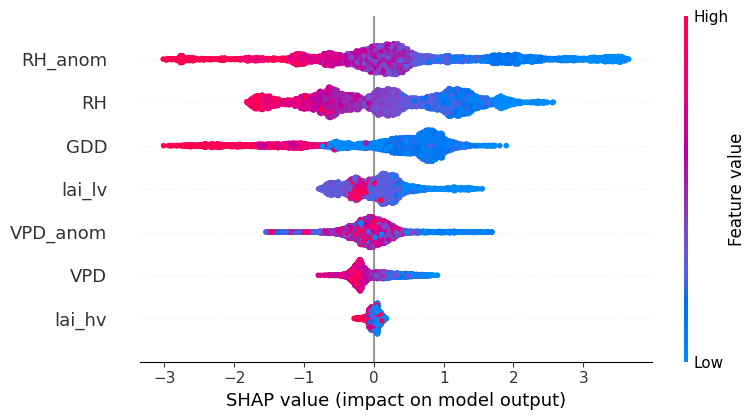

📌 SHAP Summary – hazard_drought
🔷 SW – Top 5 Features:
  • RH_anom: 0.9896000027656555
  • RH: 0.8574000000953674
  • GDD: 0.8228999972343445
  • lai_lv: 0.3127000033855438
  • VPD_anom: 0.2483000010251999
------------------------------------------------------------

🔍 SHAP Summary for SW / hazard_rain_deficit


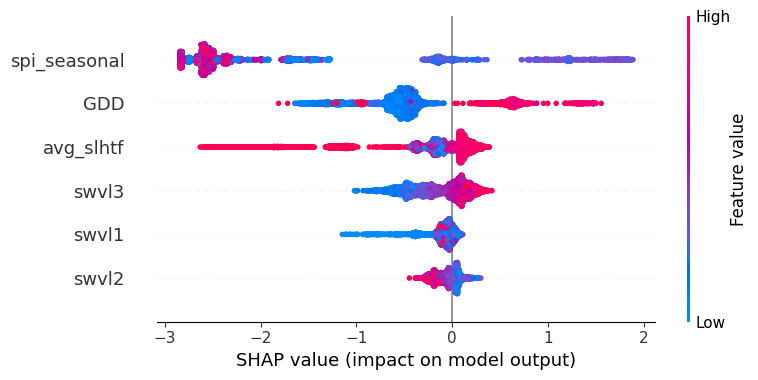

📌 SHAP Summary – hazard_rain_deficit
🔷 SW – Top 5 Features:
  • spi_seasonal: 2.1191999912261963
  • GDD: 0.6151000261306763
  • avg_slhtf: 0.3619999885559082
  • swvl3: 0.24459999799728394
  • swvl1: 0.10639999806880951
------------------------------------------------------------

🔍 SHAP Summary for SW / hazard_heatwave


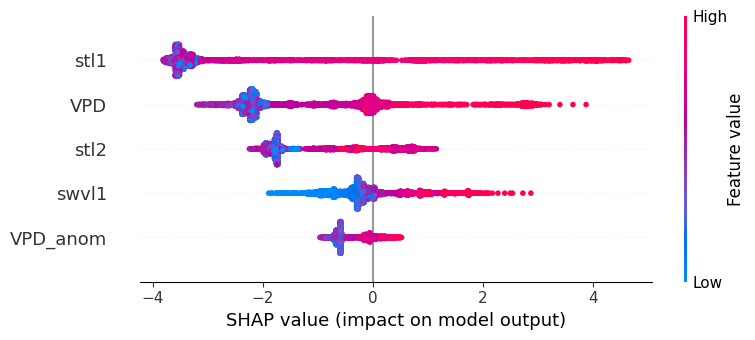

📌 SHAP Summary – hazard_heatwave
🔷 SW – Top 5 Features:
  • stl1: 2.9707000255584717
  • VPD: 1.4631999731063843
  • stl2: 1.2539000511169434
  • swvl1: 0.49950000643730164
  • VPD_anom: 0.3953999876976013
------------------------------------------------------------

🔍 SHAP Summary for SW / hazard_hot_and_dry


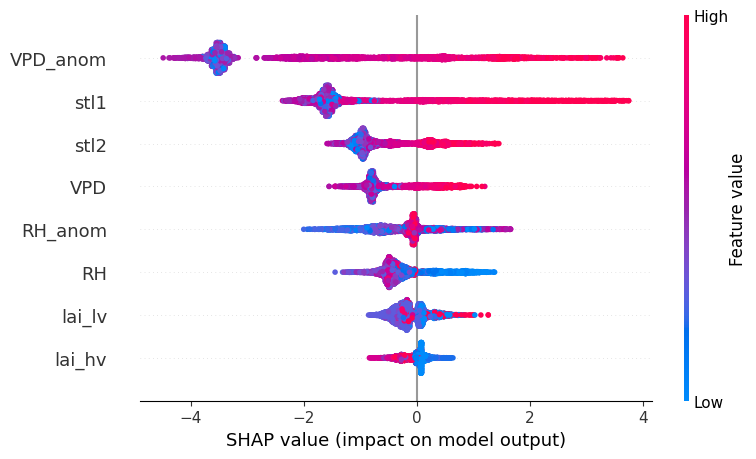

📌 SHAP Summary – hazard_hot_and_dry
🔷 SW – Top 5 Features:
  • VPD_anom: 2.386399984359741
  • stl1: 1.5047999620437622
  • stl2: 0.7663000226020813
  • VPD: 0.633400022983551
  • RH_anom: 0.47269999980926514
------------------------------------------------------------

🔍 SHAP Summary for SW / hazard_cold_spell


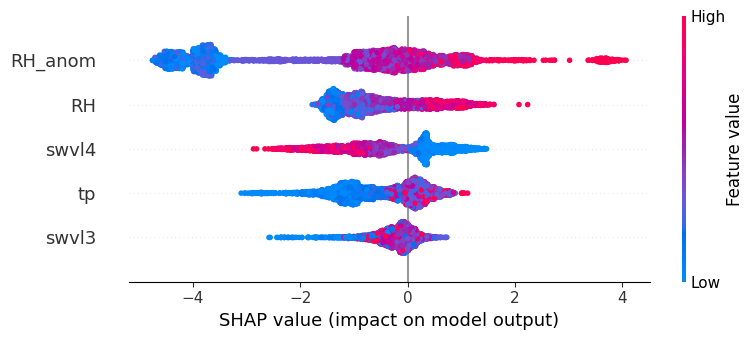

📌 SHAP Summary – hazard_cold_spell
🔷 SW – Top 5 Features:
  • RH_anom: 1.8940999507904053
  • RH: 0.8532999753952026
  • swvl4: 0.7653999924659729
  • tp: 0.6790000200271606
  • swvl3: 0.30070000886917114
------------------------------------------------------------

🔍 SHAP Summary for SW / hazard_radiation_deficit


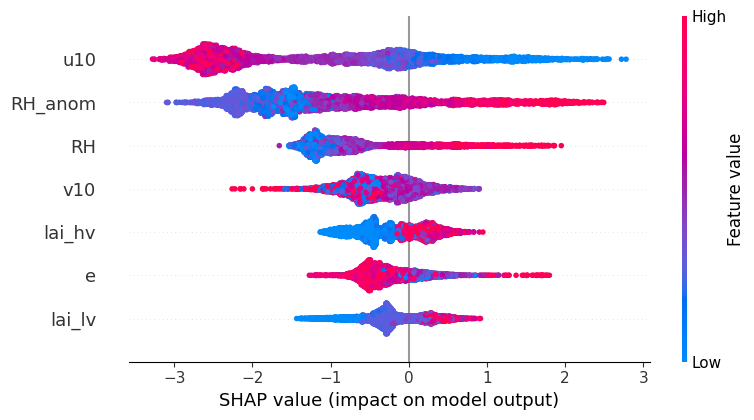

📌 SHAP Summary – hazard_radiation_deficit
🔷 SW – Top 5 Features:
  • u10: 1.448099970817566
  • RH_anom: 1.3217999935150146
  • RH: 0.8919000029563904
  • v10: 0.43700000643730164
  • lai_hv: 0.39010000228881836
------------------------------------------------------------

🔍 SHAP Summary for SW / hazard_temperature_accumulation_deficit


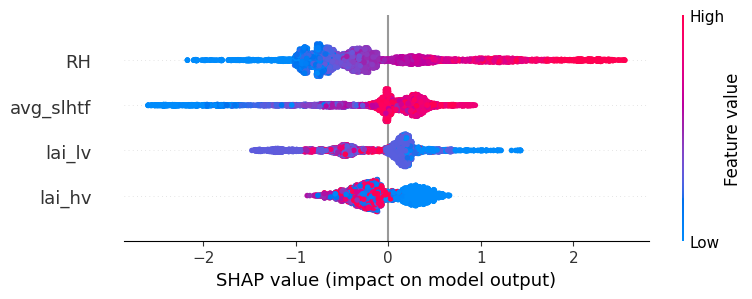

📌 SHAP Summary – hazard_temperature_accumulation_deficit
🔷 SW – Top 5 Features:
  • RH: 0.7010999917984009
  • avg_slhtf: 0.4388999938964844
  • lai_lv: 0.38510000705718994
  • lai_hv: 0.2797999978065491
------------------------------------------------------------

🔍 SHAP Summary for SE / hazard_drought


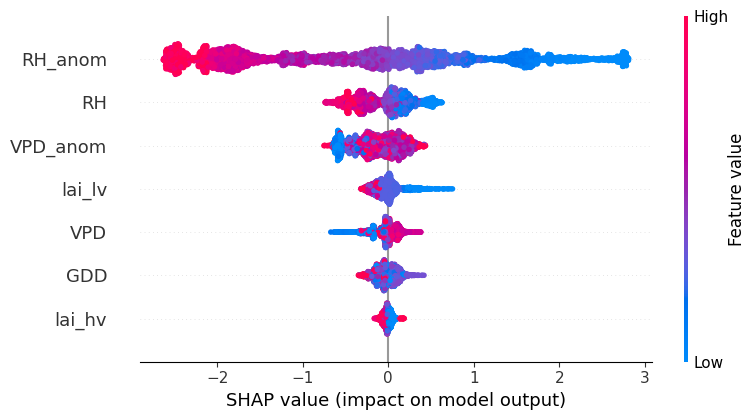

📌 SHAP Summary – hazard_drought
🔷 SE – Top 5 Features:
  • RH_anom: 1.2716000080108643
  • RH: 0.24940000474452972
  • VPD_anom: 0.24150000512599945
  • lai_lv: 0.10490000247955322
  • VPD: 0.09830000251531601
------------------------------------------------------------

🔍 SHAP Summary for SE / hazard_rain_deficit


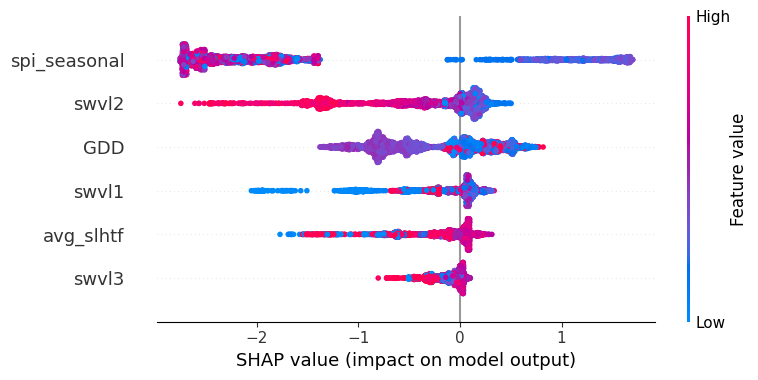

📌 SHAP Summary – hazard_rain_deficit
🔷 SE – Top 5 Features:
  • spi_seasonal: 2.054800033569336
  • swvl2: 0.4893999993801117
  • GDD: 0.4814999997615814
  • swvl1: 0.26109999418258667
  • avg_slhtf: 0.24289999902248383
------------------------------------------------------------

🔍 SHAP Summary for SE / hazard_heatwave


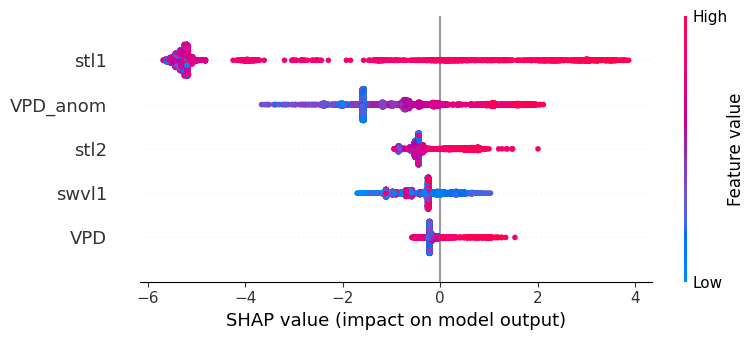

📌 SHAP Summary – hazard_heatwave
🔷 SE – Top 5 Features:
  • stl1: 4.3979997634887695
  • VPD_anom: 1.1339999437332153
  • stl2: 0.4986000061035156
  • swvl1: 0.46880000829696655
  • VPD: 0.25049999356269836
------------------------------------------------------------

🔍 SHAP Summary for SE / hazard_hot_and_dry


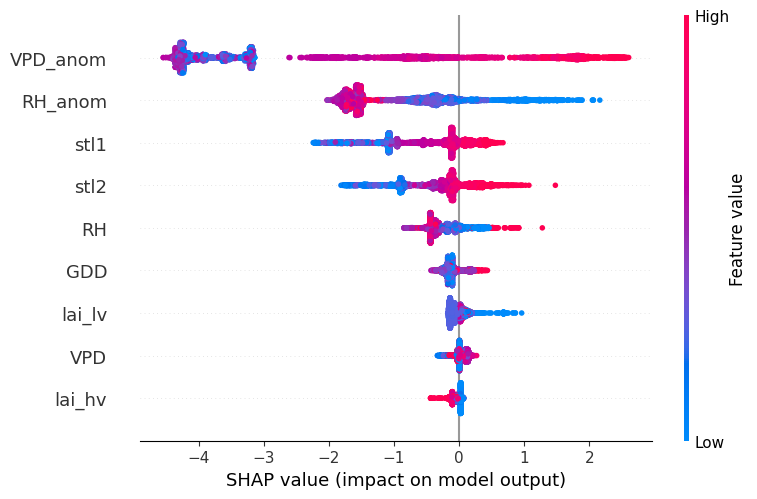

📌 SHAP Summary – hazard_hot_and_dry
🔷 SE – Top 5 Features:
  • VPD_anom: 2.8708999156951904
  • RH_anom: 1.1131999492645264
  • stl1: 0.5609999895095825
  • stl2: 0.42500001192092896
  • RH: 0.2944999933242798
------------------------------------------------------------

🔍 SHAP Summary for SE / hazard_cold_spell


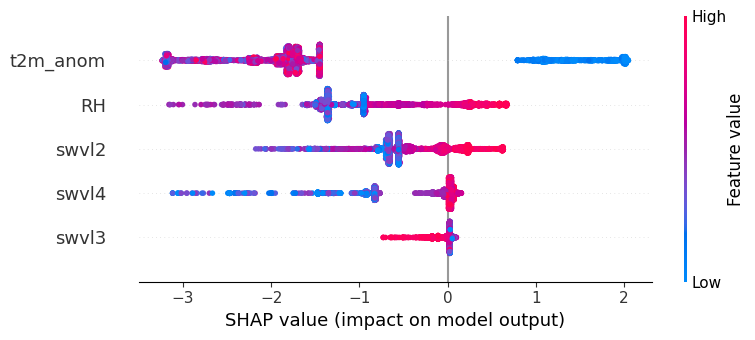

📌 SHAP Summary – hazard_cold_spell
🔷 SE – Top 5 Features:
  • t2m_anom: 1.9214999675750732
  • RH: 0.9979000091552734
  • swvl2: 0.5024999976158142
  • swvl4: 0.3384000062942505
  • swvl3: 0.05530000105500221
------------------------------------------------------------

🔍 SHAP Summary for SE / hazard_radiation_deficit


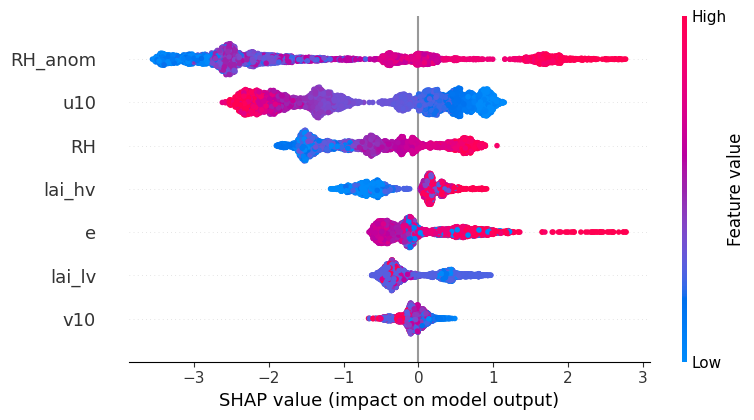

📌 SHAP Summary – hazard_radiation_deficit
🔷 SE – Top 5 Features:
  • RH_anom: 1.910599946975708
  • u10: 1.1172000169754028
  • RH: 0.8407999873161316
  • lai_hv: 0.45249998569488525
  • e: 0.4219000041484833
------------------------------------------------------------

🔍 SHAP Summary for SE / hazard_temperature_accumulation_deficit


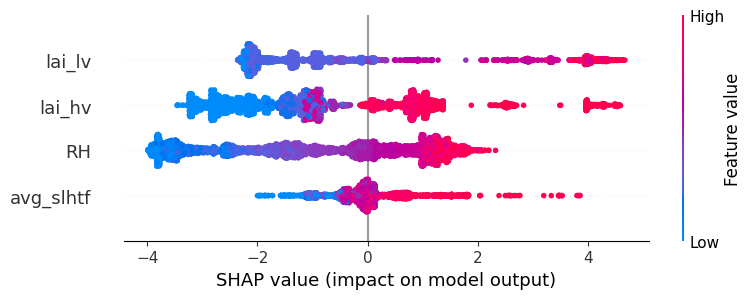

📌 SHAP Summary – hazard_temperature_accumulation_deficit
🔷 SE – Top 5 Features:
  • lai_lv: 1.8361999988555908
  • lai_hv: 1.6828999519348145
  • RH: 1.6492999792099
  • avg_slhtf: 0.4235000014305115
------------------------------------------------------------



In [ ]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

shap_summary_texts = []

for key, result in cv_results.items():
    region, hazard = key
    model = result['best_model']
    if model is None:
        print(f"⚠️ No model found for {region} / {hazard}")
        continue

    # داده‌ی ورودی SHAP باید با داده‌ی آموزش هماهنگ باشد
    df = data[region]
    features = shap_top_features.get(key)
    if not features:
        continue

    X = df[features].copy().dropna()
    X_scaled = StandardScaler().fit_transform(X)  # دوباره‌سازی همان استانداردسازی

    X_df = pd.DataFrame(X_scaled, columns=features)

    print(f"🔍 SHAP Summary for {region} / {hazard}")
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_df)

    shap.summary_plot(shap_values, X_df, show=True)

    # خلاصه متنی
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    top_idx = mean_abs_shap.argsort()[::-1][:5]
    top_features = [(features[i], round(mean_abs_shap[i], 4)) for i in top_idx]

    summary = f"📌 SHAP Summary – {hazard}\n🔷 {region} – Top 5 Features:"
    for name, val in top_features:
        summary += f"\n  • {name}: {val}"
    print(summary + "\n" + "-"*60 + "\n")

    shap_summary_texts.append(summary)


📊 SHAP Summary – hazard_drought / NW


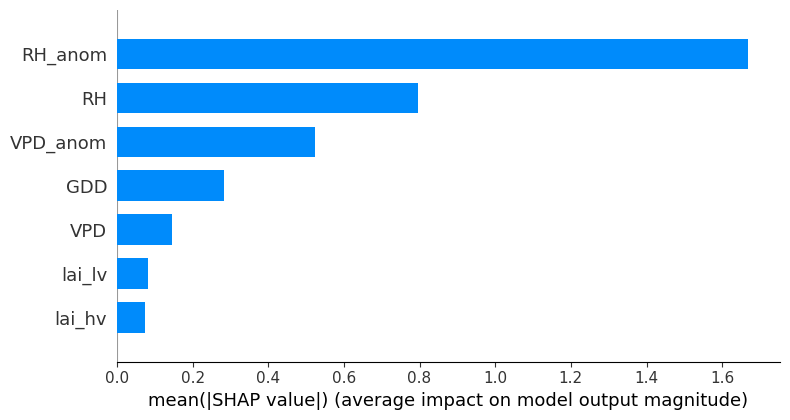

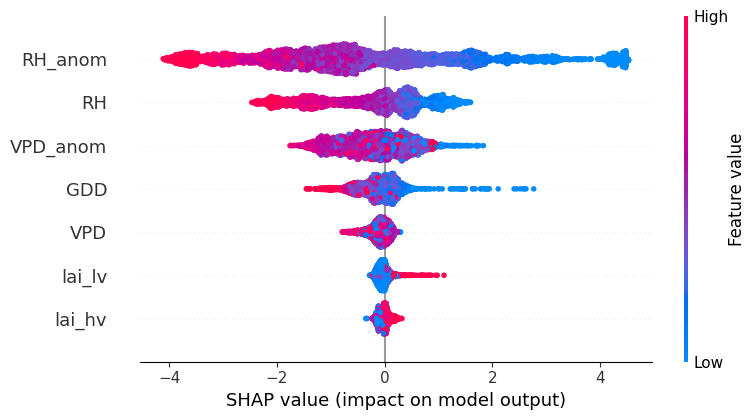

📊 SHAP Summary – hazard_rain_deficit / NW


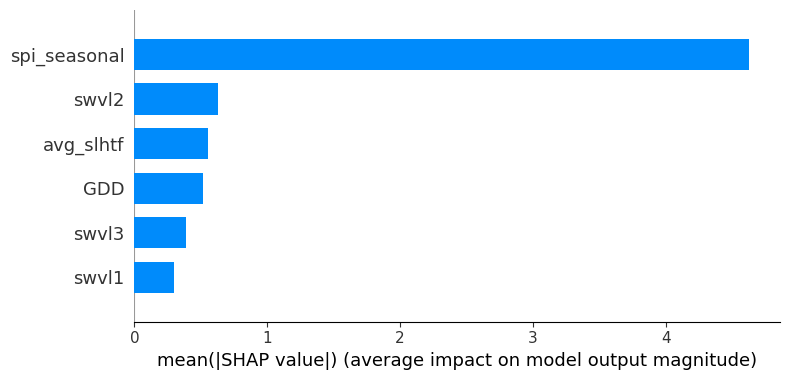

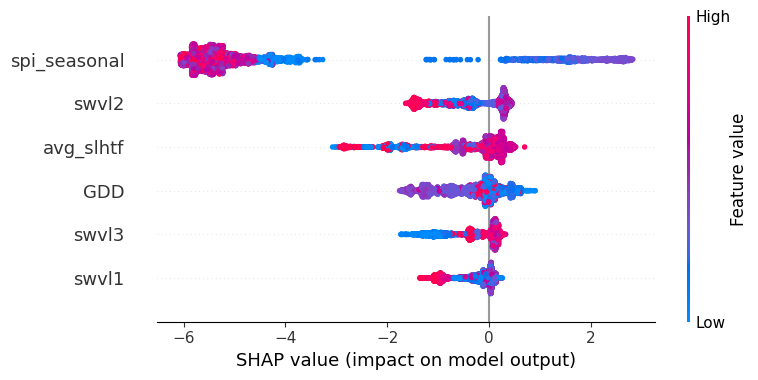

📊 SHAP Summary – hazard_heatwave / NW


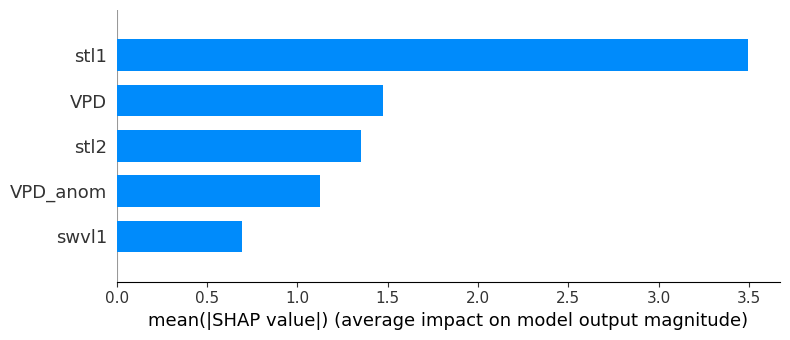

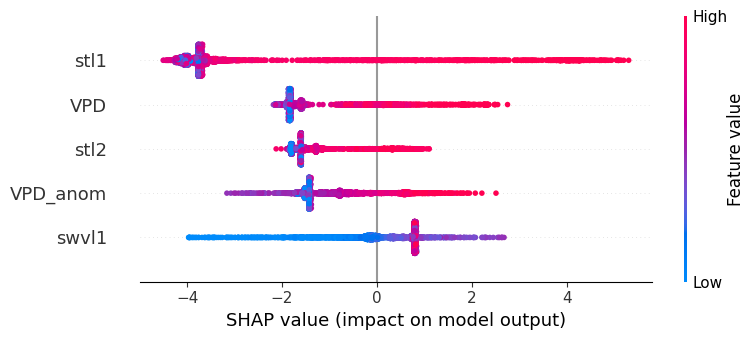

📊 SHAP Summary – hazard_hot_and_dry / NW


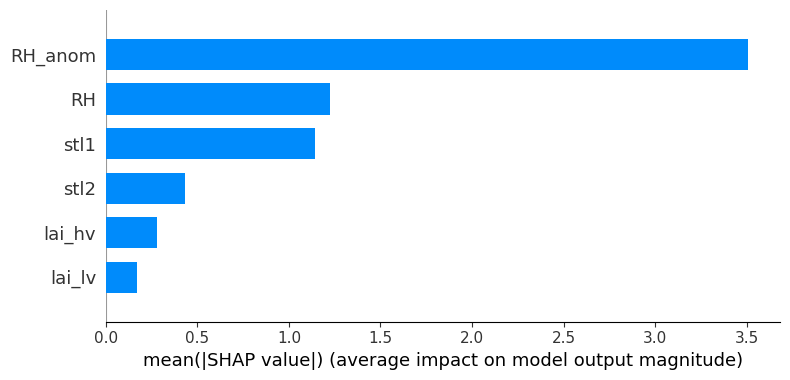

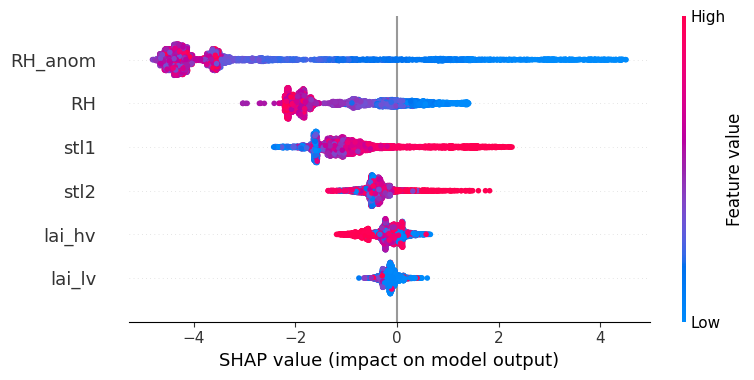

📊 SHAP Summary – hazard_cold_spell / NW


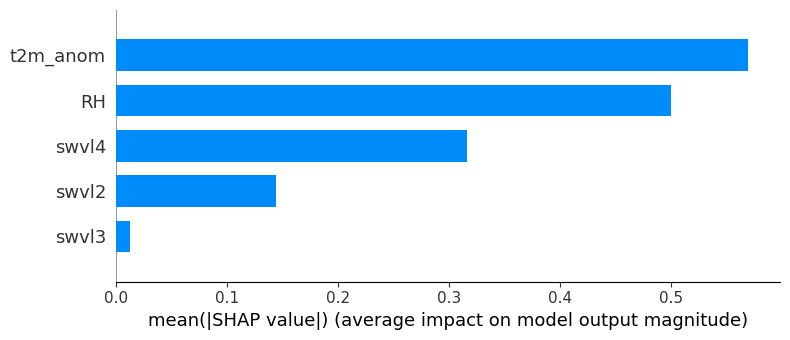

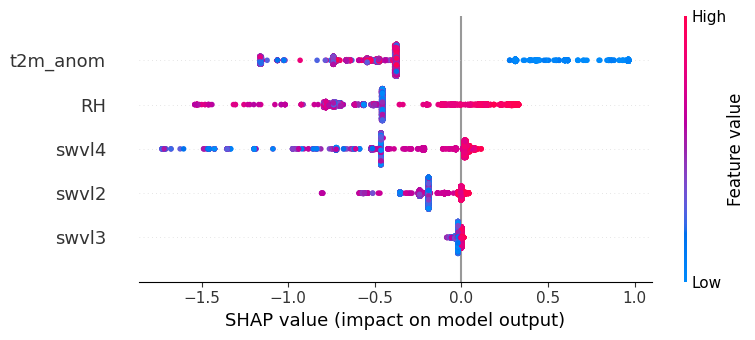

📊 SHAP Summary – hazard_radiation_deficit / NW


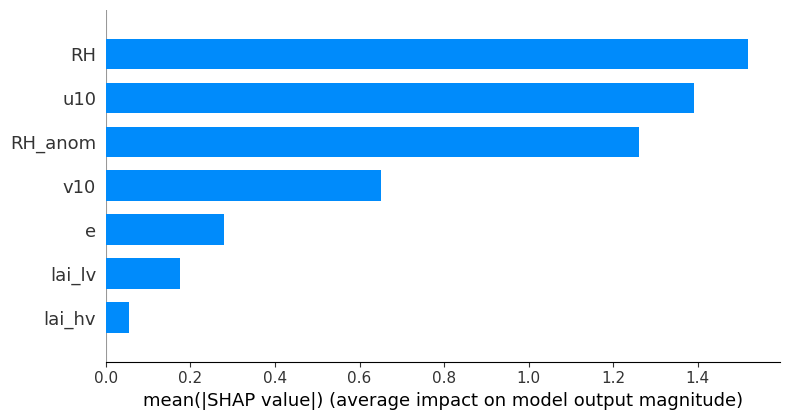

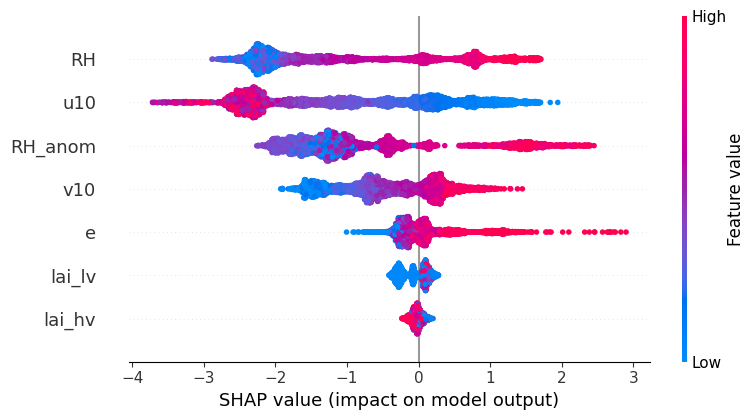

📊 SHAP Summary – hazard_temperature_accumulation_deficit / NW


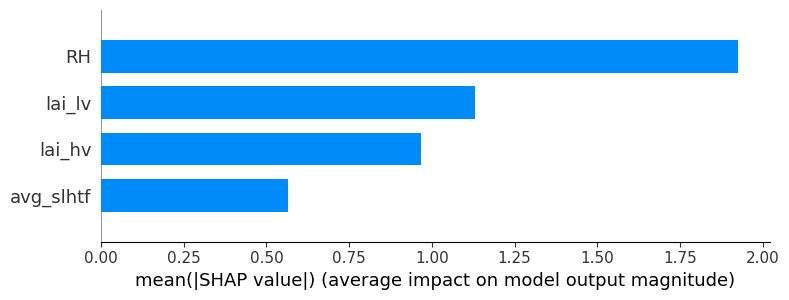

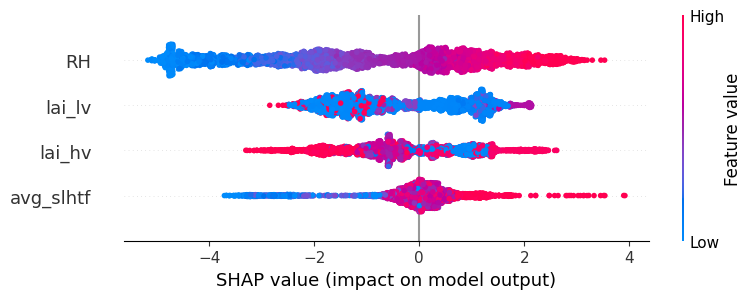

📊 SHAP Summary – hazard_drought / NE


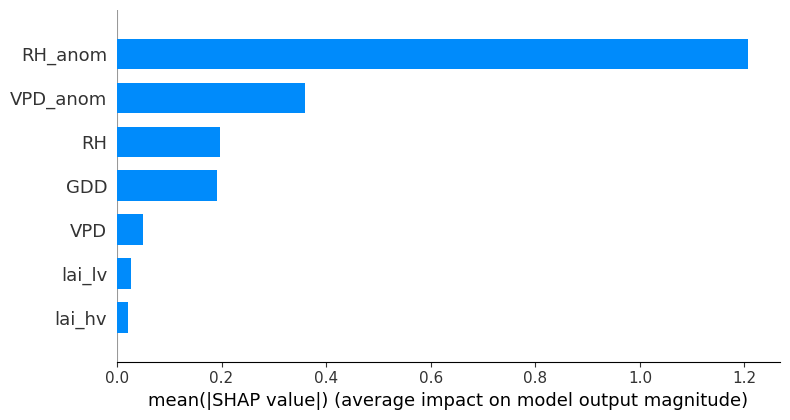

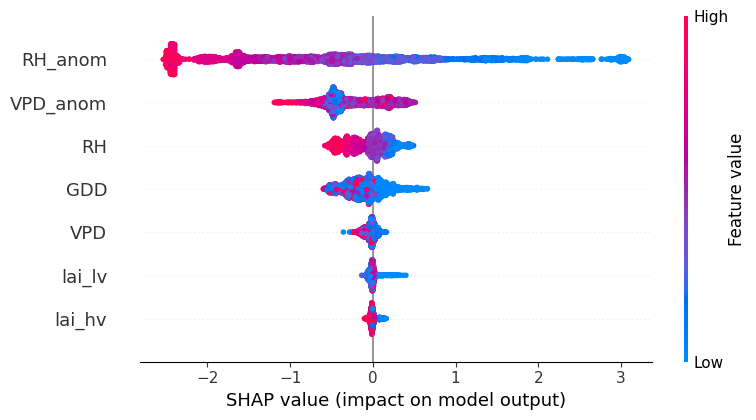

📊 SHAP Summary – hazard_rain_deficit / NE


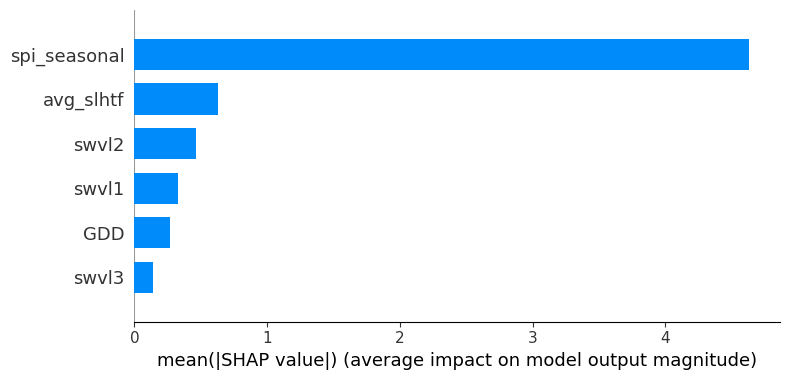

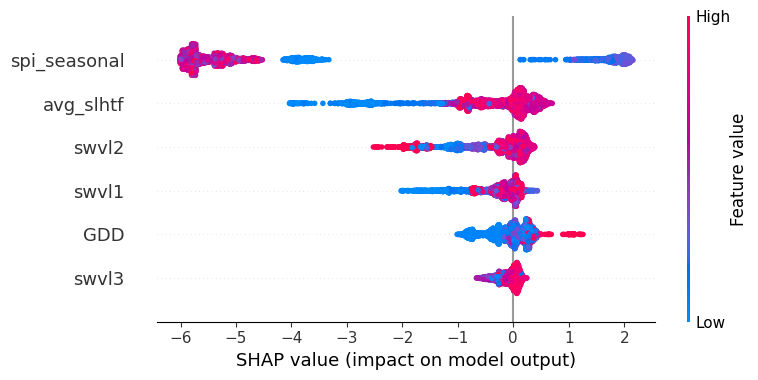

📊 SHAP Summary – hazard_heatwave / NE


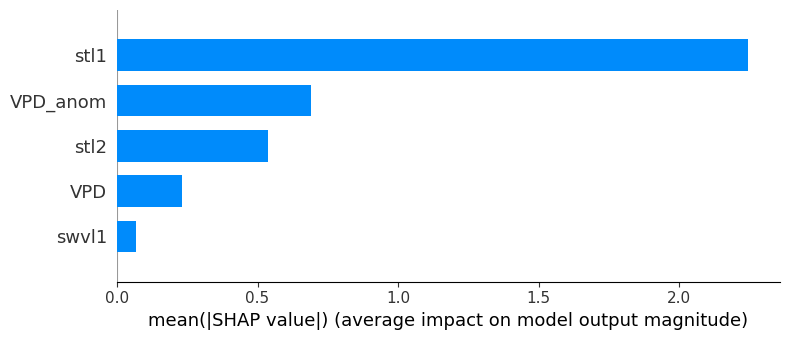

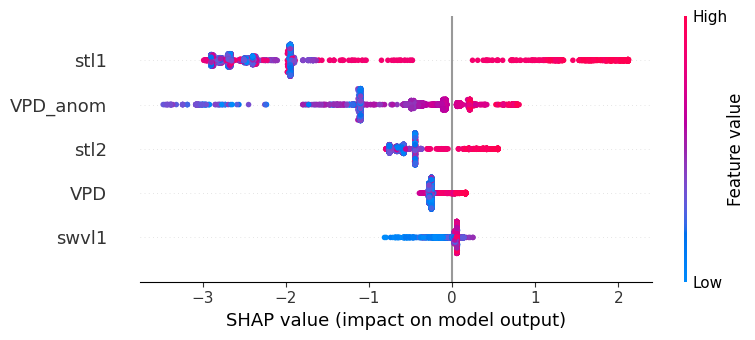

📊 SHAP Summary – hazard_hot_and_dry / NE


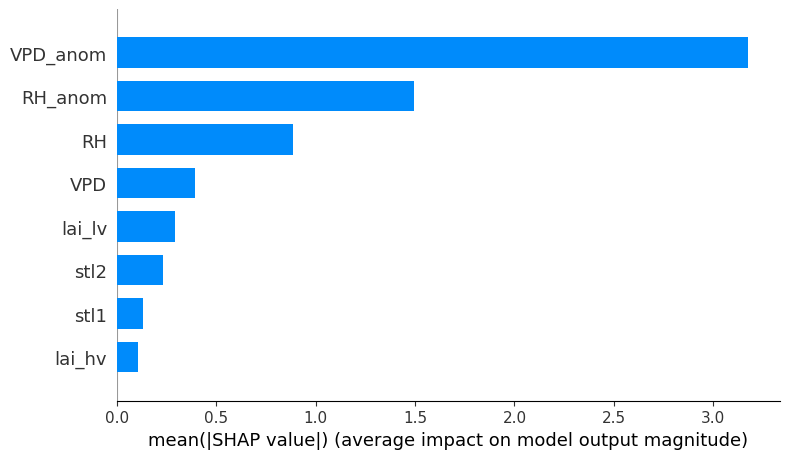

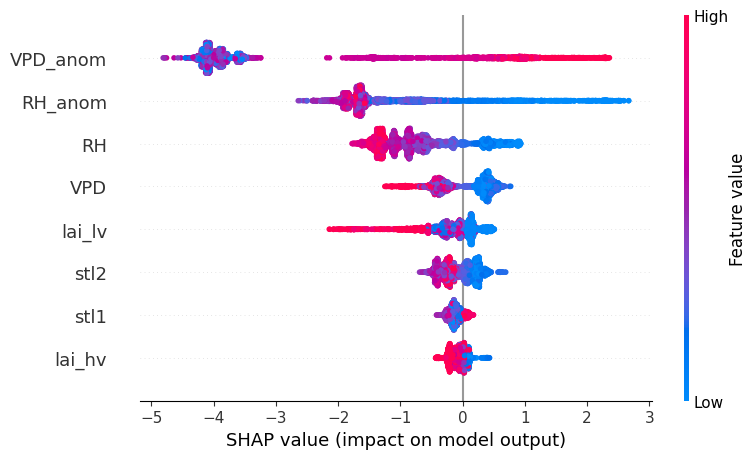

📊 SHAP Summary – hazard_cold_spell / NE


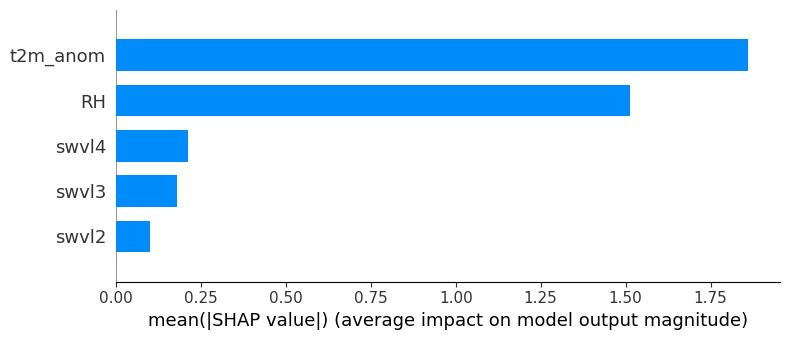

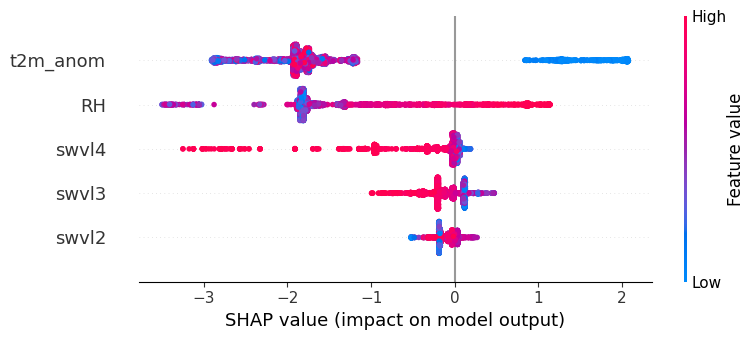

📊 SHAP Summary – hazard_radiation_deficit / NE


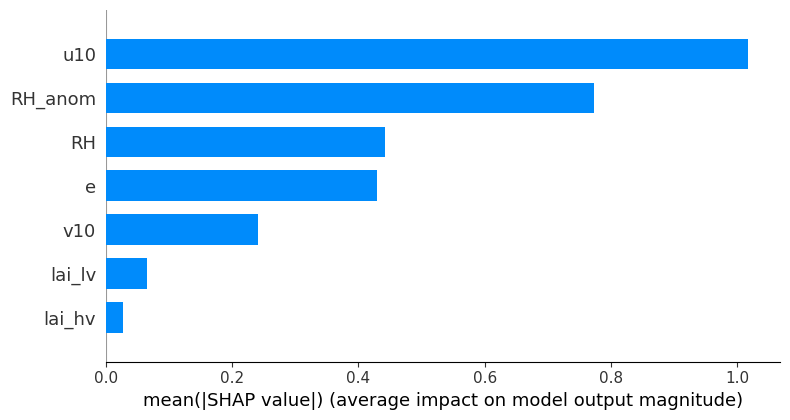

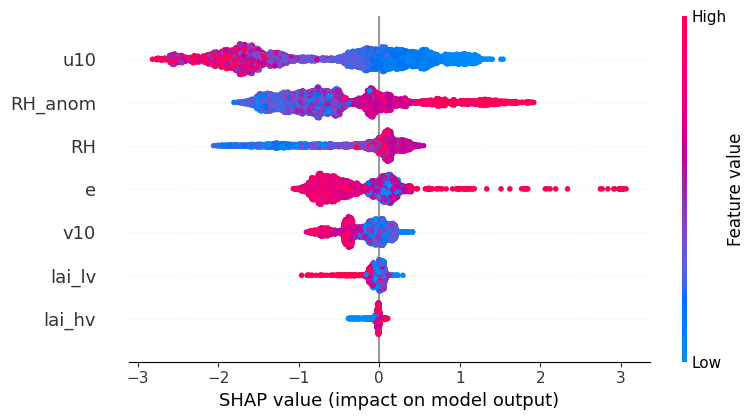

📊 SHAP Summary – hazard_temperature_accumulation_deficit / NE


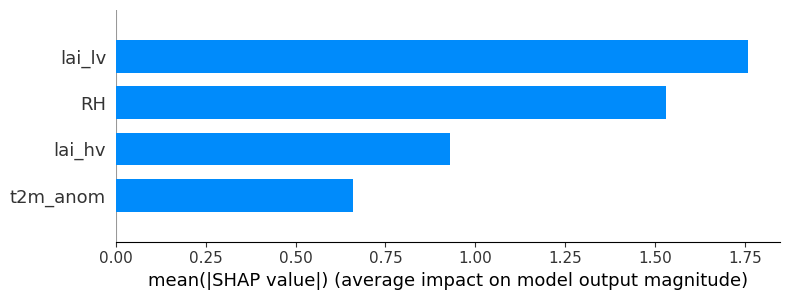

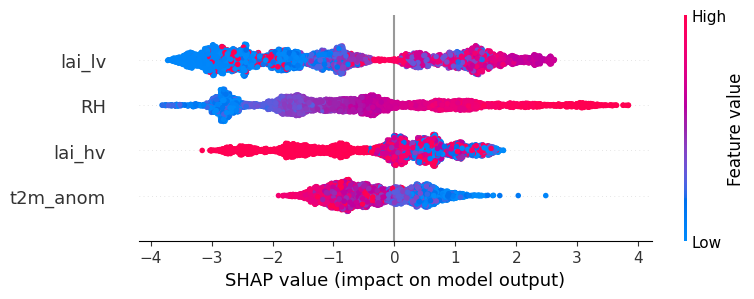

📊 SHAP Summary – hazard_drought / SW


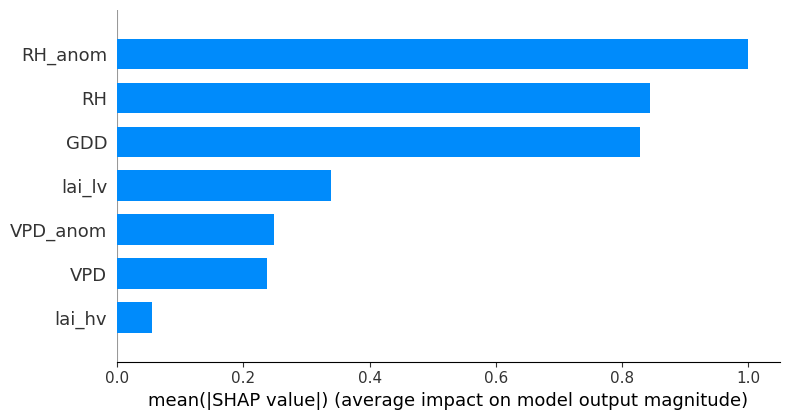

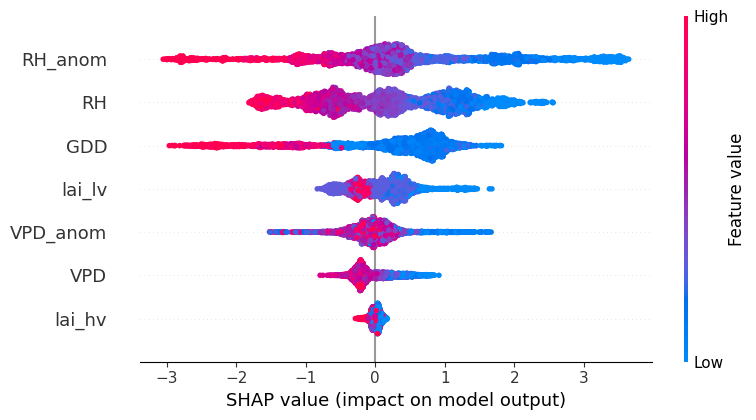

📊 SHAP Summary – hazard_rain_deficit / SW


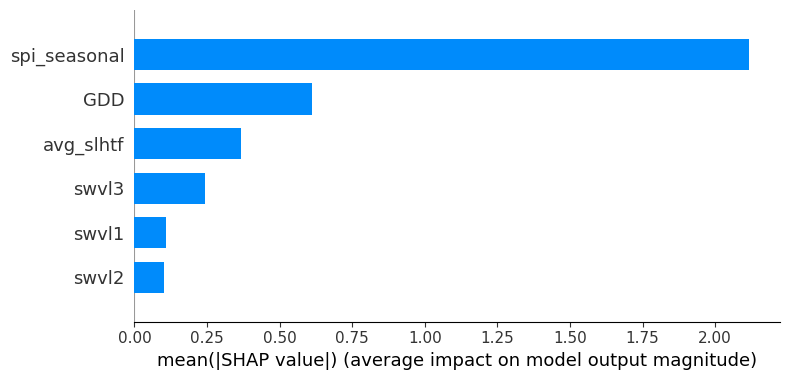

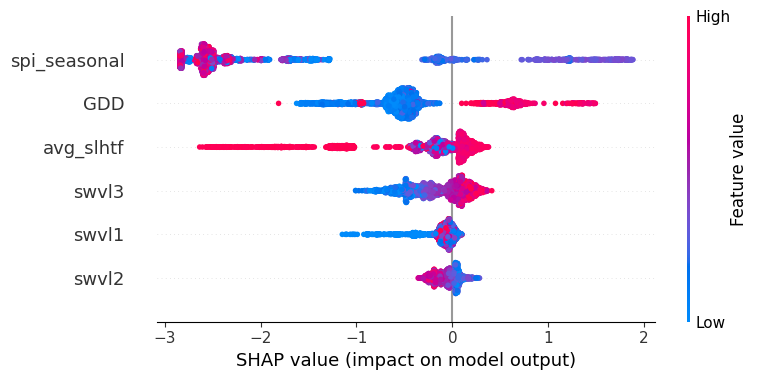

📊 SHAP Summary – hazard_heatwave / SW


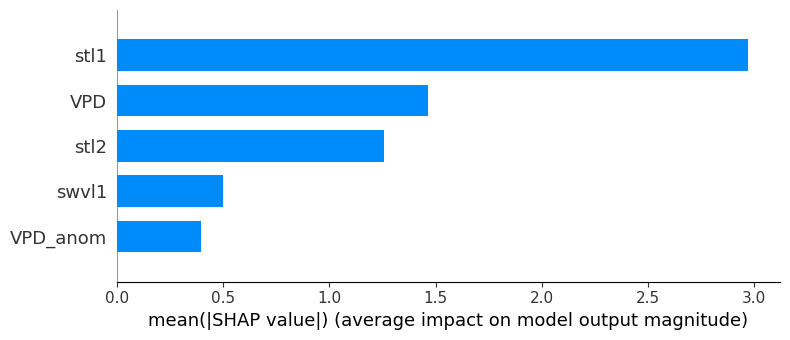

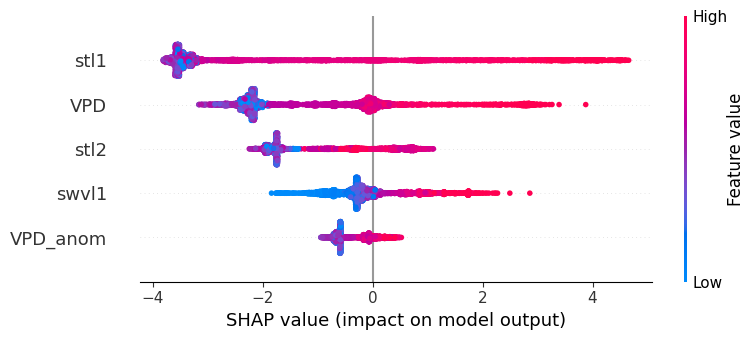

📊 SHAP Summary – hazard_hot_and_dry / SW


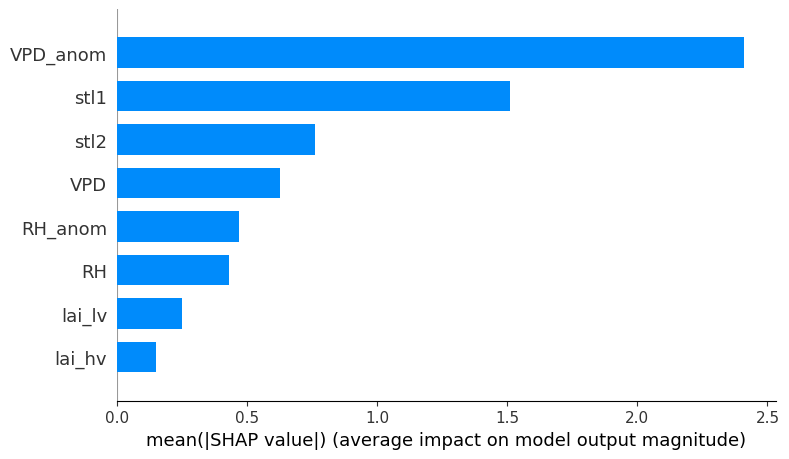

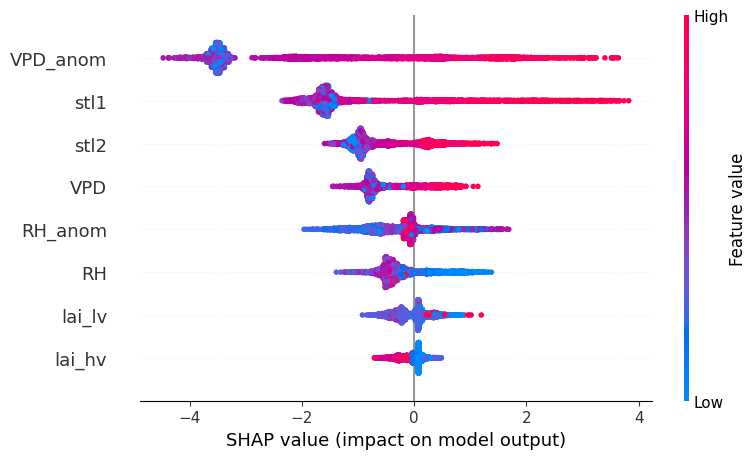

📊 SHAP Summary – hazard_cold_spell / SW


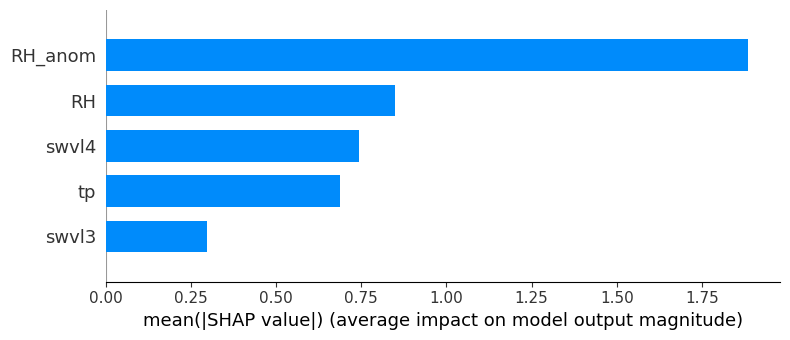

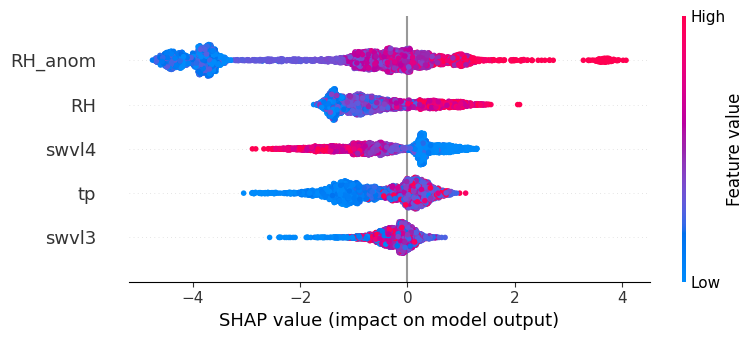

📊 SHAP Summary – hazard_radiation_deficit / SW


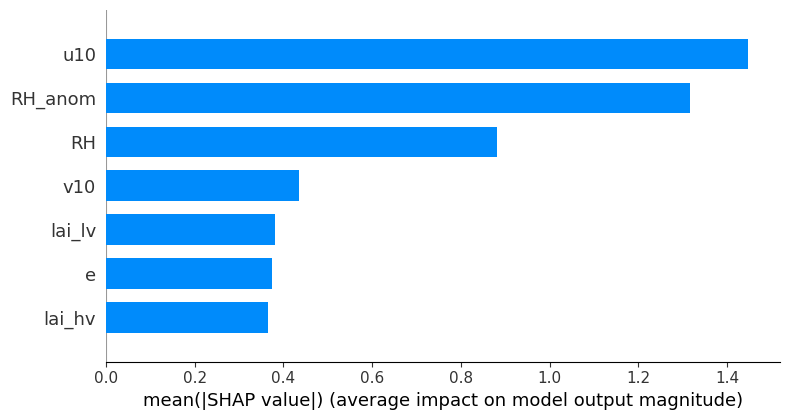

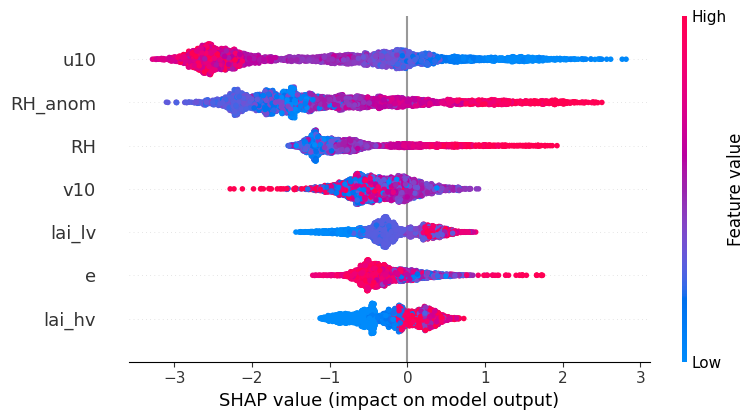

📊 SHAP Summary – hazard_temperature_accumulation_deficit / SW


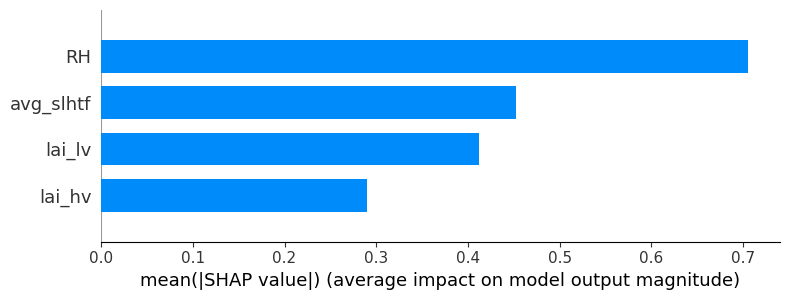

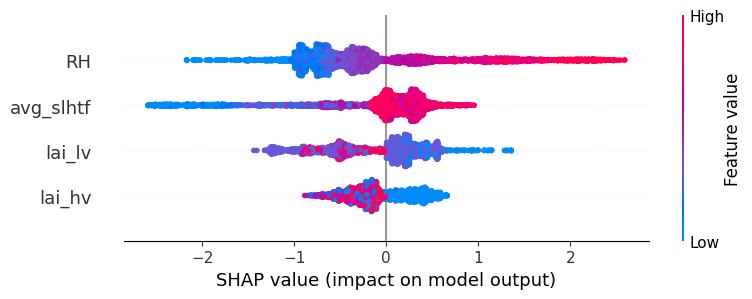

📊 SHAP Summary – hazard_drought / SE


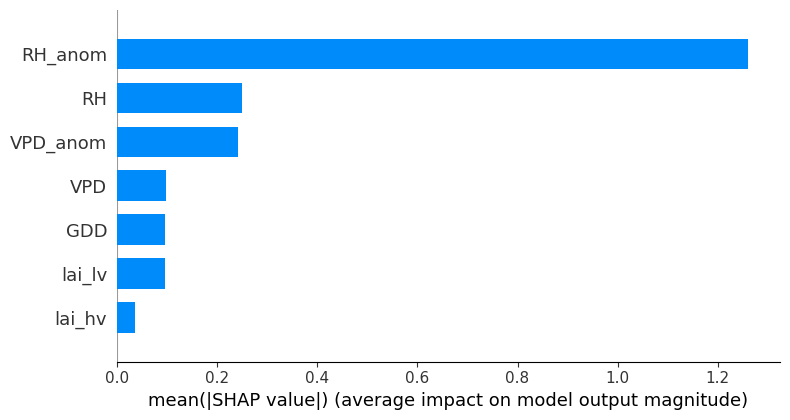

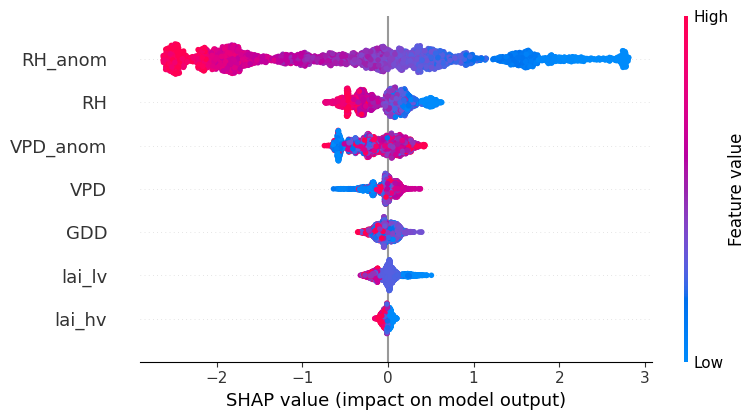

📊 SHAP Summary – hazard_rain_deficit / SE


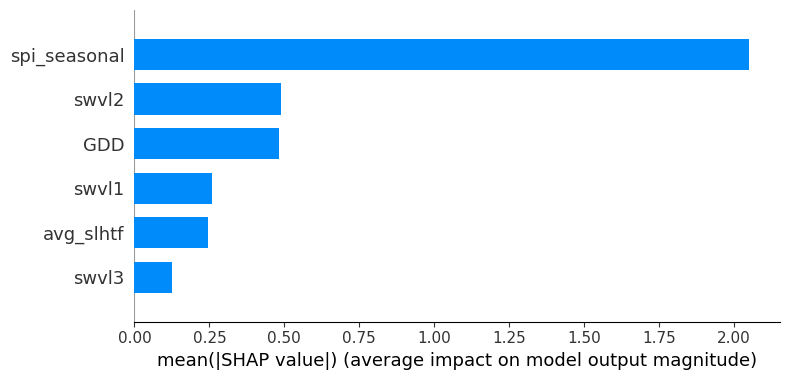

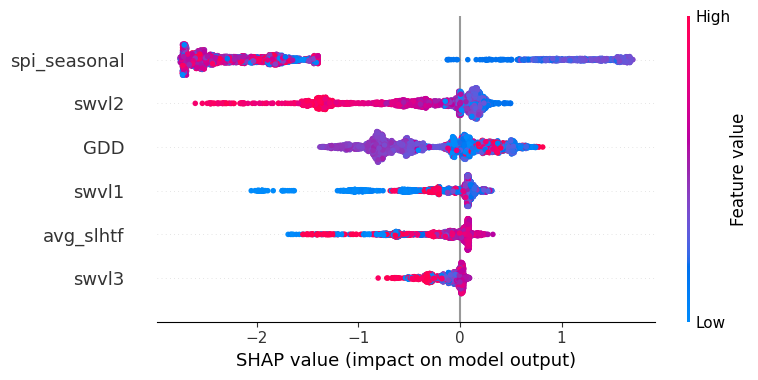

📊 SHAP Summary – hazard_heatwave / SE


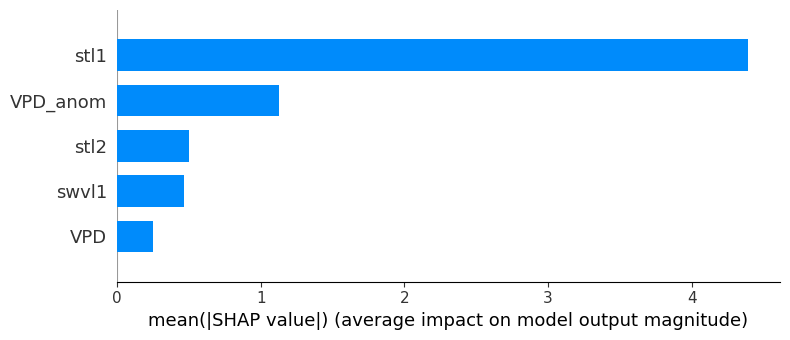

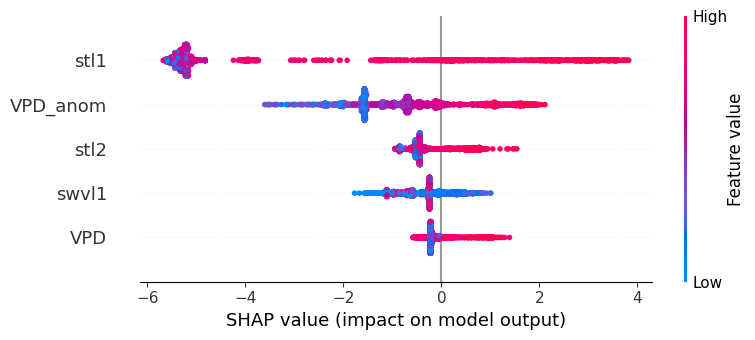

📊 SHAP Summary – hazard_hot_and_dry / SE


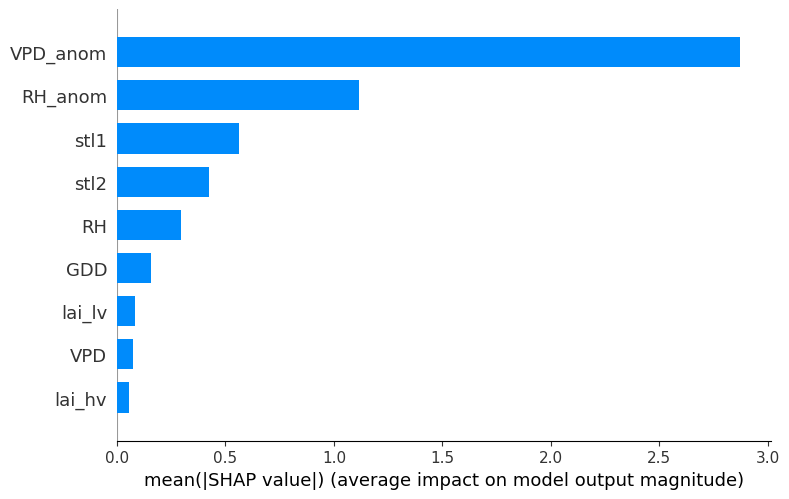

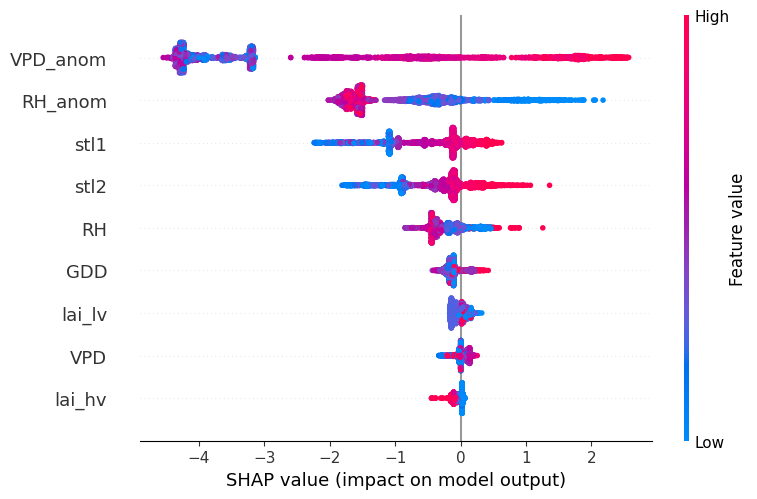

📊 SHAP Summary – hazard_cold_spell / SE


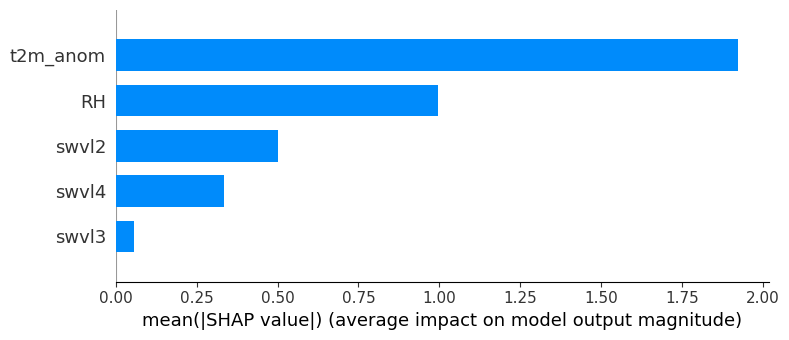

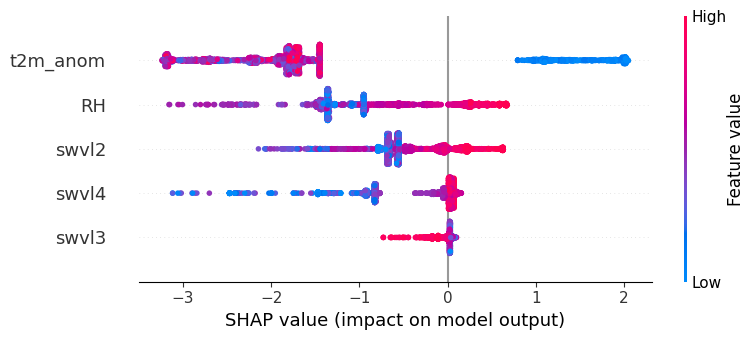

📊 SHAP Summary – hazard_radiation_deficit / SE


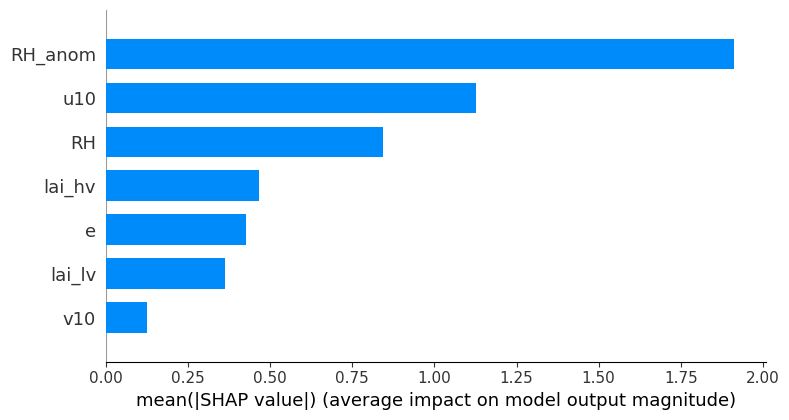

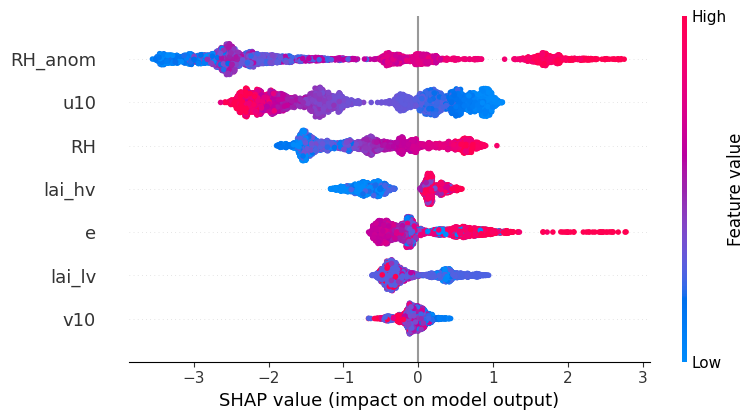

📊 SHAP Summary – hazard_temperature_accumulation_deficit / SE


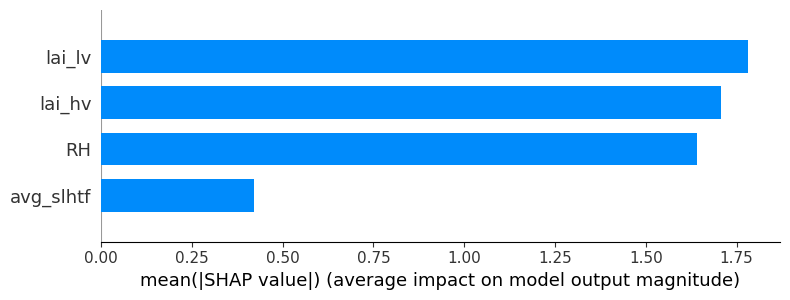

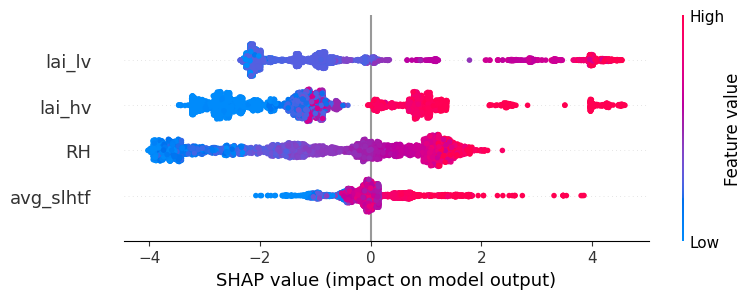

In [ ]:
import shap
import matplotlib.pyplot as plt
import pandas as pd

# نمایش نتایج برای هر region و hazard
for region in regions:
    for hazard in hazards:
        key = (region, hazard)

        if key not in prepared_data or key not in cv_results:
            continue

        model = cv_results[key].get('best_model')
        if model is None:
            print(f"⚠️ No trained model found for {region} / {hazard}")
            continue

        print(f"📊 SHAP Summary – {hazard} / {region}")

        # داده‌ها
        X = prepared_data[key]['X_train']
        feature_names = prepared_data[key]['feature_names']
        X_df = pd.DataFrame(X, columns=feature_names)

        # محاسبه مقادیر SHAP با TreeExplainer
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_df)

        # نمودار میله‌ای SHAP (Bar)
        shap.summary_plot(shap_values, X_df, plot_type='bar', max_display=10)
        plt.show()

        # نمودار BeeSwarm
        shap.summary_plot(shap_values, X_df, max_display=10)
        plt.show()


In [ ]:
from sklearn.metrics import f1_score, roc_auc_score
import pandas as pd
import numpy as np

final_results = []

for region in regions:
    for hazard in hazards:
        key = (region, hazard)
        if key not in prepared_data or key not in cv_results:
            continue

        model = cv_results[key].get('best_model')
        if model is None:
            print(f"⚠️ No best_model found for {key}")
            continue

        X_train = prepared_data[key]['X_train']
        y_train = prepared_data[key]['y_train']
        X_test = prepared_data[key]['X_test']
        y_test = prepared_data[key]['y_test']

        # پیش‌بینی
        y_pred_train = model.predict(X_train)
        y_pred_test = model.predict(X_test)

        # احتمال (در صورت پشتیبانی)
        try:
            y_prob_test = model.predict_proba(X_test)[:, 1]
            auc = roc_auc_score(y_test, y_prob_test)
        except:
            auc = None

        f1_train = f1_score(y_train, y_pred_train)
        f1_test = f1_score(y_test, y_pred_test)

        final_results.append({
            'Region': region,
            'Hazard': hazard,
            'F1_Train': round(f1_train, 3),
            'F1_Test': round(f1_test, 3),
            'AUC_Test': round(auc, 3) if auc is not None else 'N/A',
            'Support_Test': int(y_test.sum())
        })

# ساخت جدول خروجی
final_df = pd.DataFrame(final_results).sort_values(by=['Region', 'Hazard']).reset_index(drop=True)

# نمایش در نوت‌بوک
from IPython.display import display
display(final_df)

# ذخیره به CSV
csv_filename = "final_model_evaluation.csv"
final_df.to_csv(csv_filename, index=False)
print(f"✅ جدول نهایی ذخیره شد: {csv_filename}")

# دانلود (در Colab)
from google.colab import files
files.download(csv_filename)


,Region,Hazard,F1_Train,F1_Test,AUC_Test,Support_Test
0,NE,hazard_cold_spell,0.708,0.800,0.999,46
1,NE,hazard_drought,0.656,0.668,0.937,307
2,NE,hazard_heatwave,0.676,0.697,0.996,85
3,NE,hazard_hot_and_dry,0.651,0.667,0.992,98
4,NE,hazard_radiation_deficit,0.593,0.620,0.972,176
5,NE,hazard_rain_deficit,0.662,0.669,0.982,119
6,NE,hazard_temperature_accumulation_deficit,0.871,0.873,0.983,464
7,NW,hazard_cold_spell,0.722,0.729,0.998,35
8,NW,hazard_drought,0.818,0.808,0.955,556
9,NW,hazard_heatwave,0.909,0.891,0.999,171


✅ جدول نهایی ذخیره شد: final_model_evaluation.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import f1_score, roc_auc_score
import pandas as pd
import numpy as np

final_results = []

for region in regions:
    for hazard in hazards:
        key = (region, hazard)

        # بررسی وجود داده‌ها و مدل
        if key not in prepared_data or key not in cv_results:
            continue

        model = cv_results[key].get('best_model')
        if model is None:
            print(f"⚠️ No trained model found for {region} / {hazard}")
            continue

        # داده‌های آموزشی و آزمون
        X_train = prepared_data[key]['X_train']
        y_train = prepared_data[key]['y_train']
        X_test = prepared_data[key]['X_test']
        y_test = prepared_data[key]['y_test']

        # پیش‌بینی
        y_pred_train = model.predict(X_train)
        y_pred_test = model.predict(X_test)

        # احتمال برای AUC (در صورت امکان)
        try:
            y_prob_test = model.predict_proba(X_test)[:, 1]
            auc = roc_auc_score(y_test, y_prob_test)
        except Exception:
            auc = None

        # محاسبه F1
        f1_train = f1_score(y_train, y_pred_train)
        f1_test = f1_score(y_test, y_pred_test)

        final_results.append({
            'Region': region,
            'Hazard': hazard,
            'F1_Train': round(f1_train, 3),
            'F1_Test': round(f1_test, 3),
            'AUC_Test': round(auc, 3) if auc is not None else 'N/A',
            'Support_Test': int(y_test.sum())
        })

# تبدیل لیست نتایج به DataFrame
final_df = pd.DataFrame(final_results).sort_values(by=['Region', 'Hazard']).reset_index(drop=True)

# نمایش در نوت‌بوک
from IPython.display import display
display(final_df)

# ذخیره به فایل CSV
csv_filename = "final_model_evaluation.csv"
final_df.to_csv(csv_filename, index=False)
print(f"✅ جدول نهایی ذخیره شد: {csv_filename}")

# دانلود فایل در Colab
from google.colab import files
files.download(csv_filename)


,Region,Hazard,F1_Train,F1_Test,AUC_Test,Support_Test
0,NE,hazard_cold_spell,0.708,0.800,0.999,46
1,NE,hazard_drought,0.656,0.668,0.937,307
2,NE,hazard_heatwave,0.676,0.697,0.996,85
3,NE,hazard_hot_and_dry,0.651,0.667,0.992,98
4,NE,hazard_radiation_deficit,0.593,0.620,0.972,176
5,NE,hazard_rain_deficit,0.662,0.669,0.982,119
6,NE,hazard_temperature_accumulation_deficit,0.871,0.873,0.983,464
7,NW,hazard_cold_spell,0.722,0.729,0.998,35
8,NW,hazard_drought,0.818,0.808,0.955,556
9,NW,hazard_heatwave,0.909,0.891,0.999,171


✅ جدول نهایی ذخیره شد: final_model_evaluation.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


📊 Confusion Matrix – NW / hazard_drought
[[1118  184]
 [  54  502]]
----------------------------------------



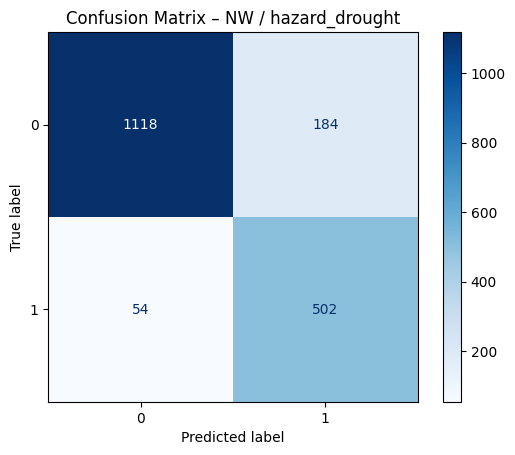

📊 Confusion Matrix – NW / hazard_rain_deficit
[[1701   83]
 [   1   73]]
----------------------------------------



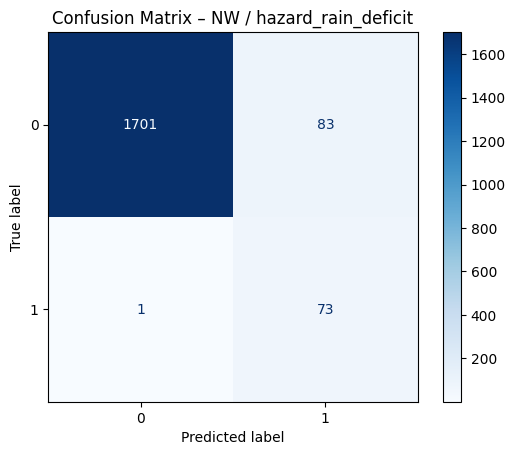

📊 Confusion Matrix – NW / hazard_heatwave
[[1645   42]
 [   0  171]]
----------------------------------------



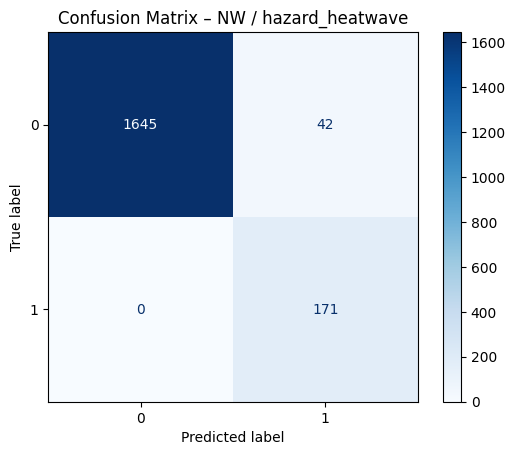

📊 Confusion Matrix – NW / hazard_hot_and_dry
[[1635   57]
 [   2  164]]
----------------------------------------



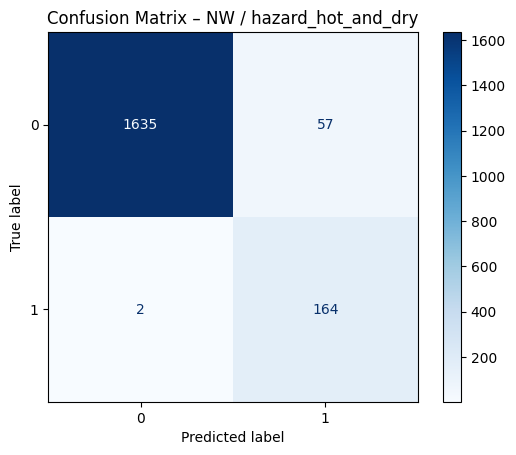

📊 Confusion Matrix – NW / hazard_cold_spell
[[1797   26]
 [   0   35]]
----------------------------------------



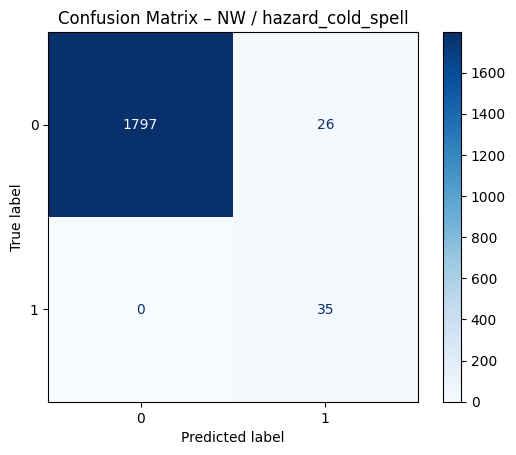

📊 Confusion Matrix – NW / hazard_radiation_deficit
[[1498  187]
 [   3  170]]
----------------------------------------



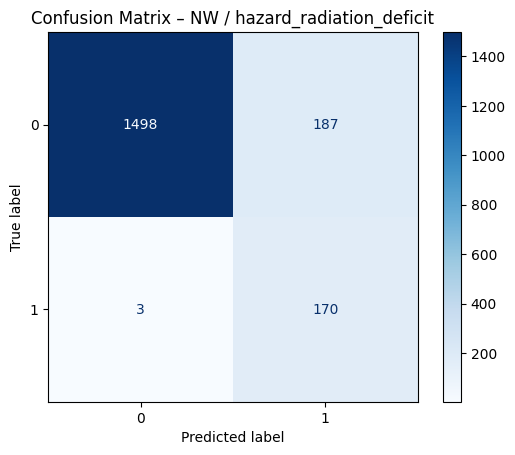

📊 Confusion Matrix – NW / hazard_temperature_accumulation_deficit
[[1254  140]
 [  21  443]]
----------------------------------------



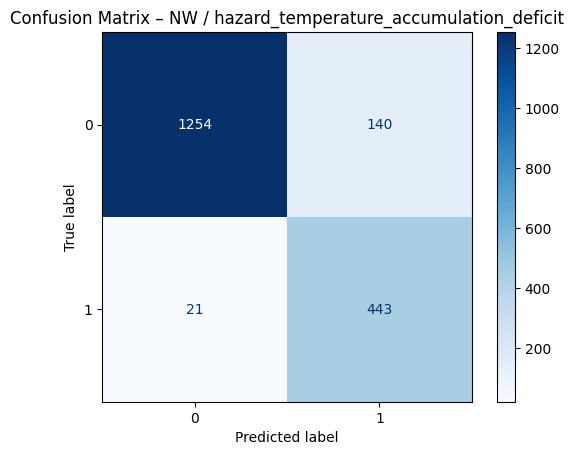

📊 Confusion Matrix – NE / hazard_drought
[[1341  209]
 [  48  259]]
----------------------------------------



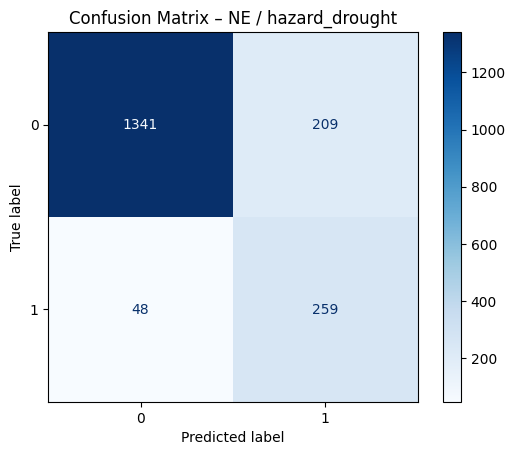

📊 Confusion Matrix – NE / hazard_rain_deficit
[[1622  116]
 [   1  118]]
----------------------------------------



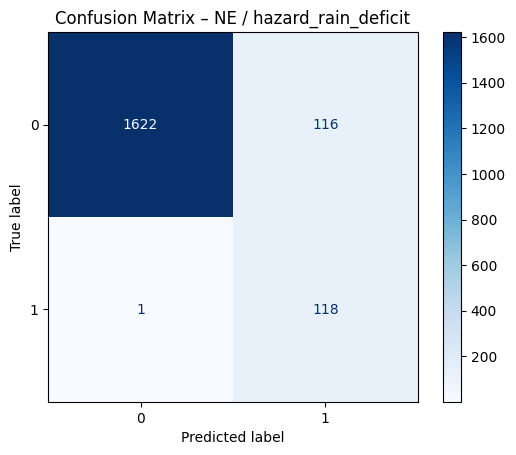

📊 Confusion Matrix – NE / hazard_heatwave
[[1698   74]
 [   0   85]]
----------------------------------------



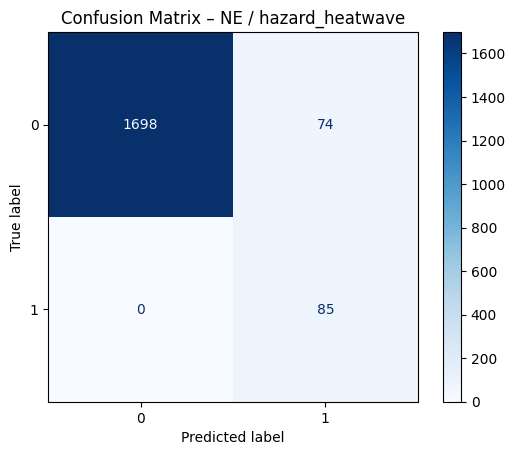

📊 Confusion Matrix – NE / hazard_hot_and_dry
[[1665   94]
 [   2   96]]
----------------------------------------



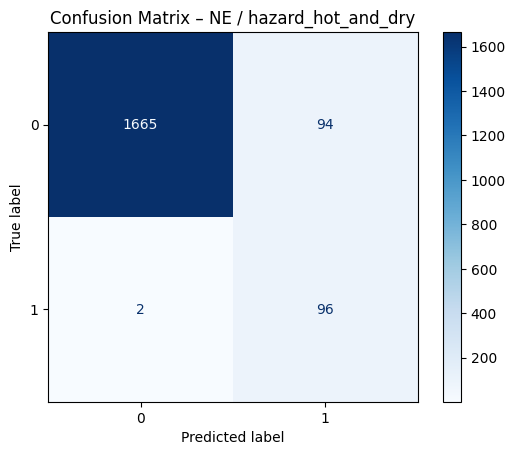

📊 Confusion Matrix – NE / hazard_cold_spell
[[1788   23]
 [   0   46]]
----------------------------------------



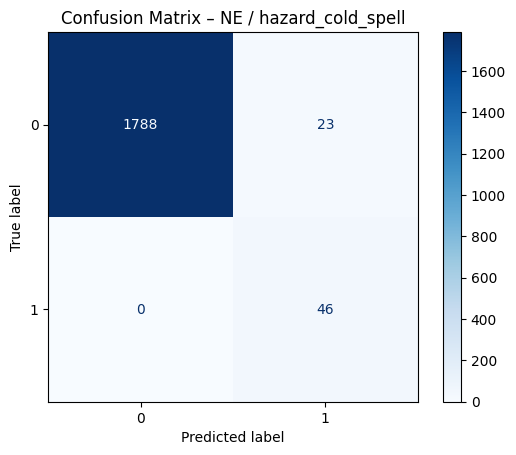

📊 Confusion Matrix – NE / hazard_radiation_deficit
[[1481  200]
 [   7  169]]
----------------------------------------



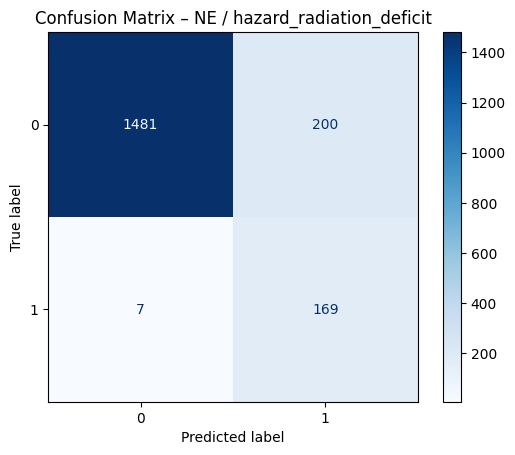

📊 Confusion Matrix – NE / hazard_temperature_accumulation_deficit
[[1310   83]
 [  40  424]]
----------------------------------------



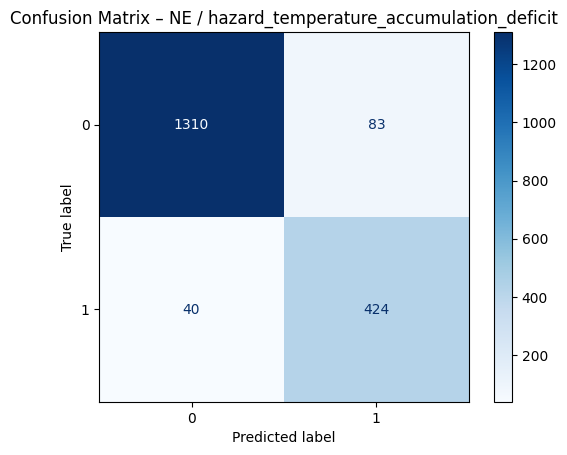

📊 Confusion Matrix – SW / hazard_drought
[[488  73]
 [ 92 921]]
----------------------------------------



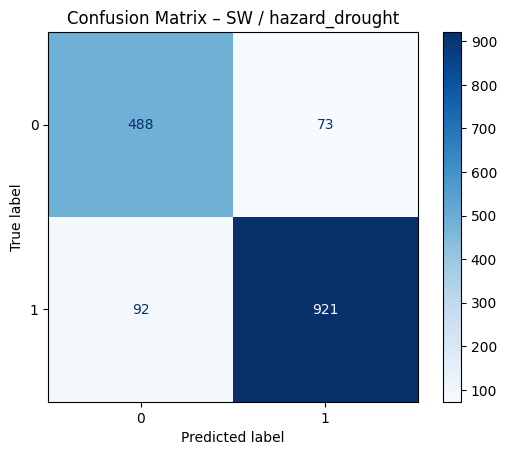

📊 Confusion Matrix – SW / hazard_rain_deficit
[[1488   40]
 [   1   45]]
----------------------------------------



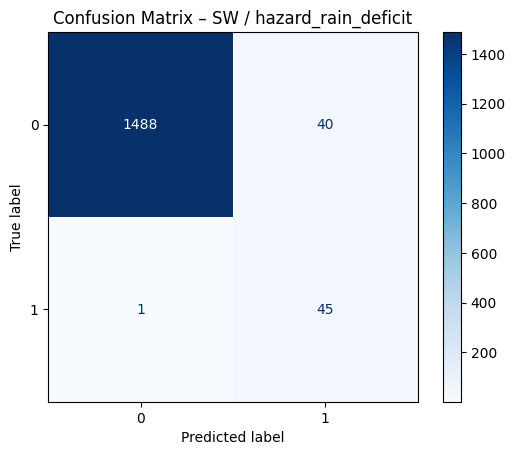

📊 Confusion Matrix – SW / hazard_heatwave
[[1248   90]
 [   9  227]]
----------------------------------------



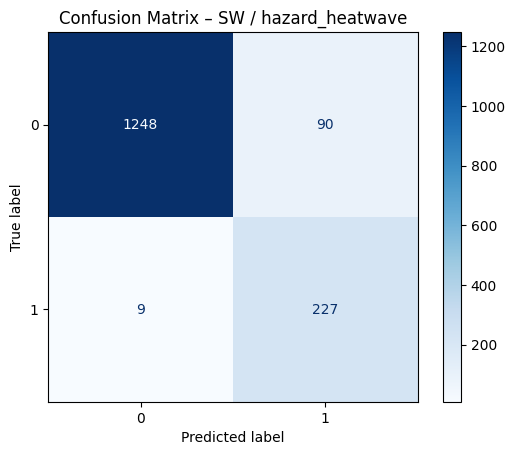

📊 Confusion Matrix – SW / hazard_hot_and_dry
[[1266   60]
 [   1  247]]
----------------------------------------



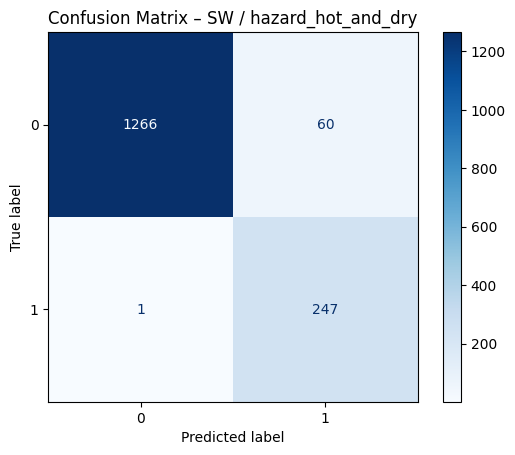

📊 Confusion Matrix – SW / hazard_cold_spell
[[1235  113]
 [   6  220]]
----------------------------------------



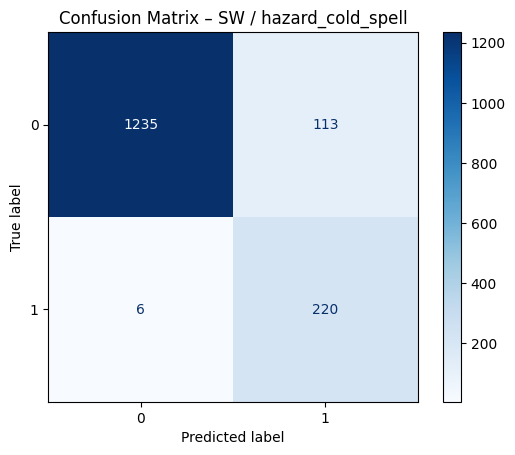

📊 Confusion Matrix – SW / hazard_radiation_deficit
[[1305  112]
 [   4  153]]
----------------------------------------



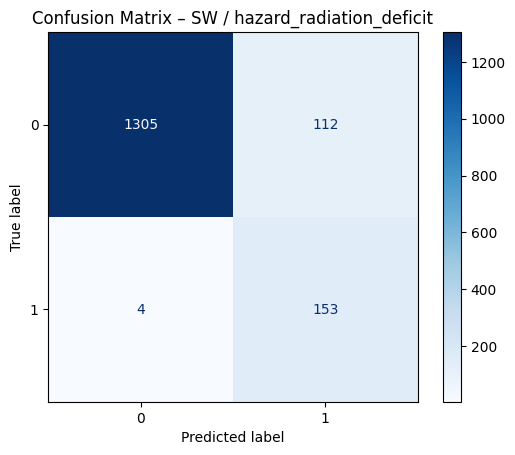

📊 Confusion Matrix – SW / hazard_temperature_accumulation_deficit
[[917 263]
 [109 285]]
----------------------------------------



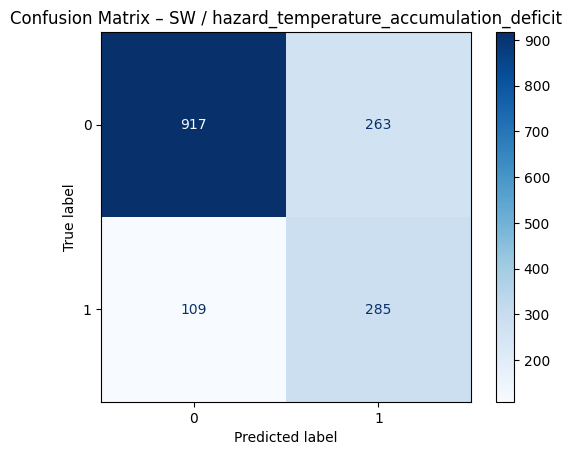

📊 Confusion Matrix – SE / hazard_drought
[[767 200]
 [ 53 374]]
----------------------------------------



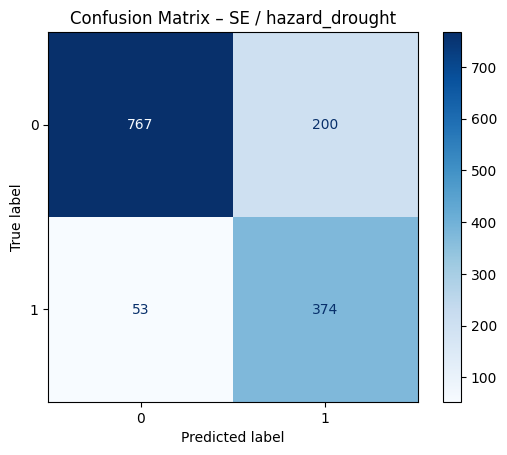

📊 Confusion Matrix – SE / hazard_rain_deficit
[[1262   67]
 [   0   65]]
----------------------------------------



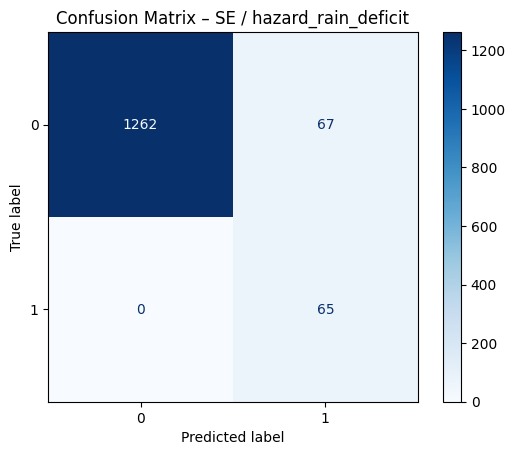

📊 Confusion Matrix – SE / hazard_heatwave
[[1164   53]
 [   1  176]]
----------------------------------------



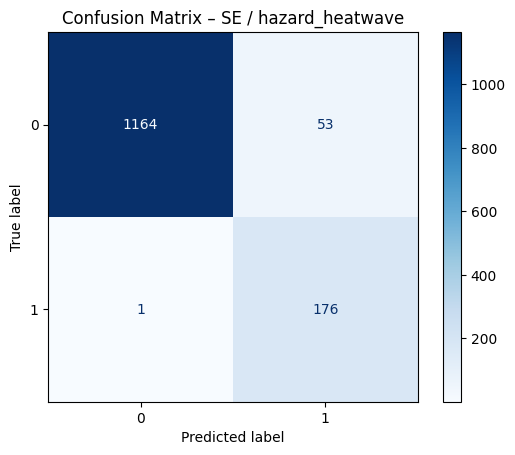

📊 Confusion Matrix – SE / hazard_hot_and_dry
[[1139  112]
 [   5  138]]
----------------------------------------



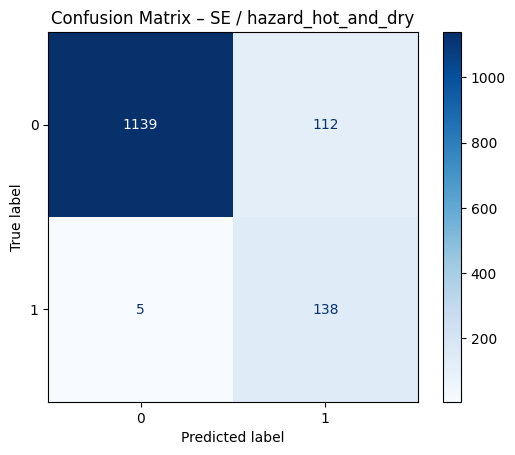

📊 Confusion Matrix – SE / hazard_cold_spell
[[1299   42]
 [   0   53]]
----------------------------------------



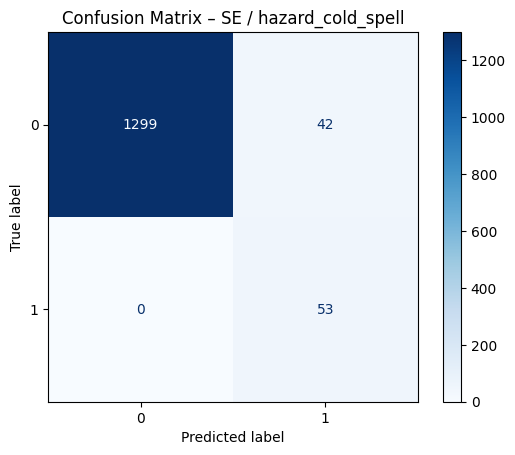

📊 Confusion Matrix – SE / hazard_radiation_deficit
[[1122  139]
 [   9  124]]
----------------------------------------



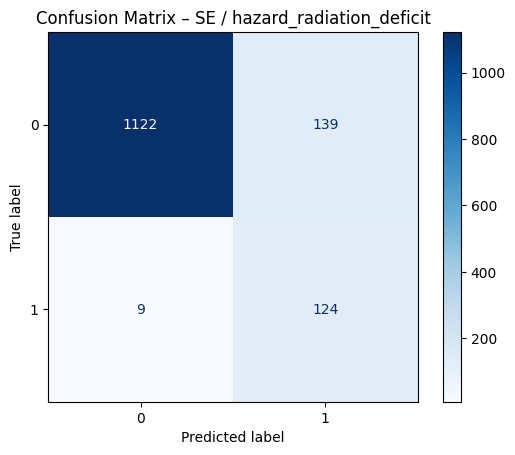

📊 Confusion Matrix – SE / hazard_temperature_accumulation_deficit
[[1005   41]
 [  12  336]]
----------------------------------------



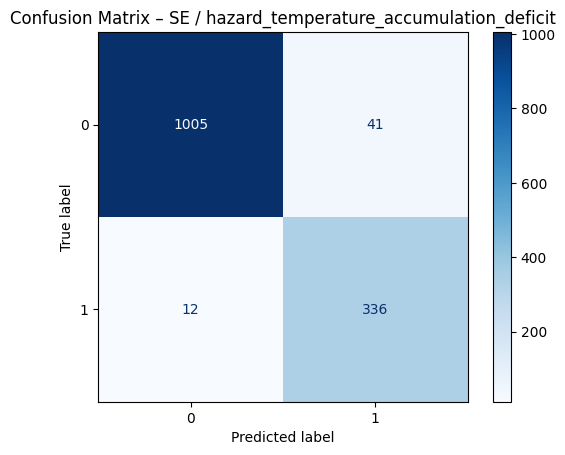


📁 خلاصه‌ی متنی confusion matrix‌ها در فایل: /content/confusion_matrices_summary.txt


In [ ]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# مسیر ذخیره گزارش متنی
output_path = "/content/confusion_matrices_summary.txt"

# باز کردن فایل برای نوشتن گزارش
with open(output_path, "w") as f:
    for region in regions:
        for hazard in hazards:
            key = (region, hazard)

            # بررسی وجود داده و مدل
            if key not in prepared_data or key not in cv_results:
                continue

            model = cv_results[key].get('best_model')
            if model is None:
                print(f"⚠️ No trained model found for {region} / {hazard}")
                continue

            X_test = prepared_data[key]['X_test']
            y_test = prepared_data[key]['y_test']

            try:
                y_pred = model.predict(X_test)
            except Exception as e:
                print(f"❌ Error in prediction for {region} / {hazard}: {e}")
                continue

            cm = confusion_matrix(y_test, y_pred)

            # چاپ در خروجی متنی
            result_header = f"📊 Confusion Matrix – {region} / {hazard}\n"
            result_body = f"{cm}\n{'-'*40}\n"
            print(result_header + result_body)
            f.write(result_header)
            f.write(result_body)

            # رسم گرافیکی Confusion Matrix
            disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
            disp.plot(cmap=plt.cm.Blues)
            plt.title(f"Confusion Matrix – {region} / {hazard}")
            plt.show()

print(f"\n📁 خلاصه‌ی متنی confusion matrix‌ها در فایل: {output_path}")
